In [ ]:
"""
Code for Appendix C: Supplementary Information
-------------------------------------------------------------------------------------------

This notebook contains the plotting code that creates supplementary figures presented in the 
'Appendix C: Supplementary Information'. The data used to make these plots can be found in 
data/processed in the root of this repository, which have been created by enso_preprocessing.py 
(or appendix_A.ipynb in the case of Figures C1 and C2).

Author: Sreevathsa G. (sg13n23@soton.ac.uk; ORCID ID: 0000-0003-4084-9677)
Last updated: 25 November 2026
"""

In [ ]:
# Standard library
from itertools import product
from pathlib import Path
import pickle
import string
import sys
import warnings

# Third-party
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm
import xarray as xr

# Local modules
REPO_ROOT = Path.cwd().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from utils import add_colorbar, format_axis, merge_pngs_vertical

# Runtime configuration
warnings.simplefilter(action="ignore", category=FutureWarning)

# Cartopy features
land_50m = cfeature.NaturalEarthFeature("physical", "land", "50m", edgecolor="face", facecolor="grey")
coast_50m = cfeature.NaturalEarthFeature("physical", "coastline", "50m", edgecolor="black", facecolor="none")

In [2]:
# Directories (relative to this notebook)
DATA_DIR = '../data/processed/'
FIG_DIR  = '../figures/'

# Dataset name lists
HIGHRESMIP_MODELS = [
    "HadGEM3-GC31-HH", "EC-Earth3P-HR", "CNRM-CM6-1-HR",
    "CMCC-CM2-VHR4", "MPI-ESM1-2-HR", "MPI-ESM1-2-XR"
]
EXP_TYPES = ['CTRL', 'HIST', 'SCEN']
HIGHRESMIP_EXPS = [f'{model}_{exp_type}' for model, exp_type in product(HIGHRESMIP_MODELS, EXP_TYPES)] # Every model paired with each experiment type
NPD_EXPS = ["NPD_eORCA025_ERA5", "NPD_eORCA025_JRA55"]
OBS = ["EN4", "ORAS5"]
BOTTOM_ROWS = [NPD_EXPS, ['ORAS5', 'EN4']] # NPD (top) and OBS (bottom) rows of the panel grids below

# Panel specs of the 8 x 6 grids in FIGURES C3-C4, C6-C7 and C8, in plotting order. Each spec is (dataset name, panel title,
# gridspec row, gridspec columns, experiment type that sets the period). Rows 0-5: HighResMIP models, one row each with
# CTRL | HIST | SCEN (2 columns each). Rows 6-7: NPD and OBS, 2 panels of 3 columns each, which follow the HIST period
PANEL_SPECS = [(f'{model}_{exp}', f'{model} | {exp}', i, slice(j * 2, (j + 1) * 2), exp)
               for i, model in enumerate(HIGHRESMIP_MODELS) for j, exp in enumerate(EXP_TYPES)]
PANEL_SPECS += [(name, name, 6 + k, slice(j * 3, (j + 1) * 3), 'HIST')
                for k, row in enumerate(BOTTOM_ROWS) for j, name in enumerate(row)]

### Figure C1: PSD vs. Red noise for each HighResMIP experiment + NPD + OBS

In [5]:
# =============================================================================
# READING IN THE PRE-COMPUTED PSD AND SHIFT-TEST RESULTS (FIGURES C1 AND C2)
# =============================================================================
# Results of the red-noise test and the phase-randomised shift test (see appendix_A.ipynb for the calculations)
# res:             one entry per dataset (each HighResMIP experiment, NPD run and OBS product), holding its Welch PSD,
#                  the red-noise 5-95% envelope and median, the lag-1 autocorrelation and the p-value of the dominant peak
# shift_test_dict: one entry per (model, comparison) pair, with comparison = CTRL-HIST, HIST-SCEN, CTRL-OBS or HIST-OBS

with open(f"{DATA_DIR}PSD_PEAK_TEST_RED_NOISE.pkl", 'rb') as f:
    res = pickle.load(f)

with open(f"{DATA_DIR}PSD_PEAK_SHIFT_TEST_PHASE_RANDOM.pkl", 'rb') as f:
    shift_test_dict = pickle.load(f)

# Welch settings: 14-yr Hann segments, 75% overlap, zero-padded to 3 times segment length. The dominant period is
# searched within 0.5-14 yr, the same band as in the red-noise and shift tests and in Tables 2-3 and Figs. 2i/7g
PSD_KW = dict(nperseg=168, period_min=0.5, period_max=14.0, fs=12.0, noverlap_frac=0.75, nfft=3*168)

# Spacing of the zero-padded Welch frequency grid: fs / nfft = 12 / 504 = 1/42 cycles per year
# Every dominant frequency is a whole number k of these steps, and so is every shift between two runs
DF = PSD_KW['fs'] / PSD_KW['nfft']

# Units: the input is monthly, but fs = 12 samples per year, so frequencies are in cycles per year (Nyquist = 6 cycles/yr)
# Welch 'density' scaling then gives PSD in °C² per (cycle per year), which equals °C² yr since a cycle is dimensionless
PSD_LABEL   = r'PSD (°C$^{2}$ (cycles yr$^{-1}$)$^{-1}$)'
SHIFT_LABEL = r'|$\Delta f$| (cycles yr$^{-1}$)'

ALPHA = 0.05 # Significance level: a result counts as significant when p <= ALPHA (used by every test and figure below)

Processing datasets: 0it [00:00, ?it/s]

Processing datasets: 0it [00:00, ?it/s]

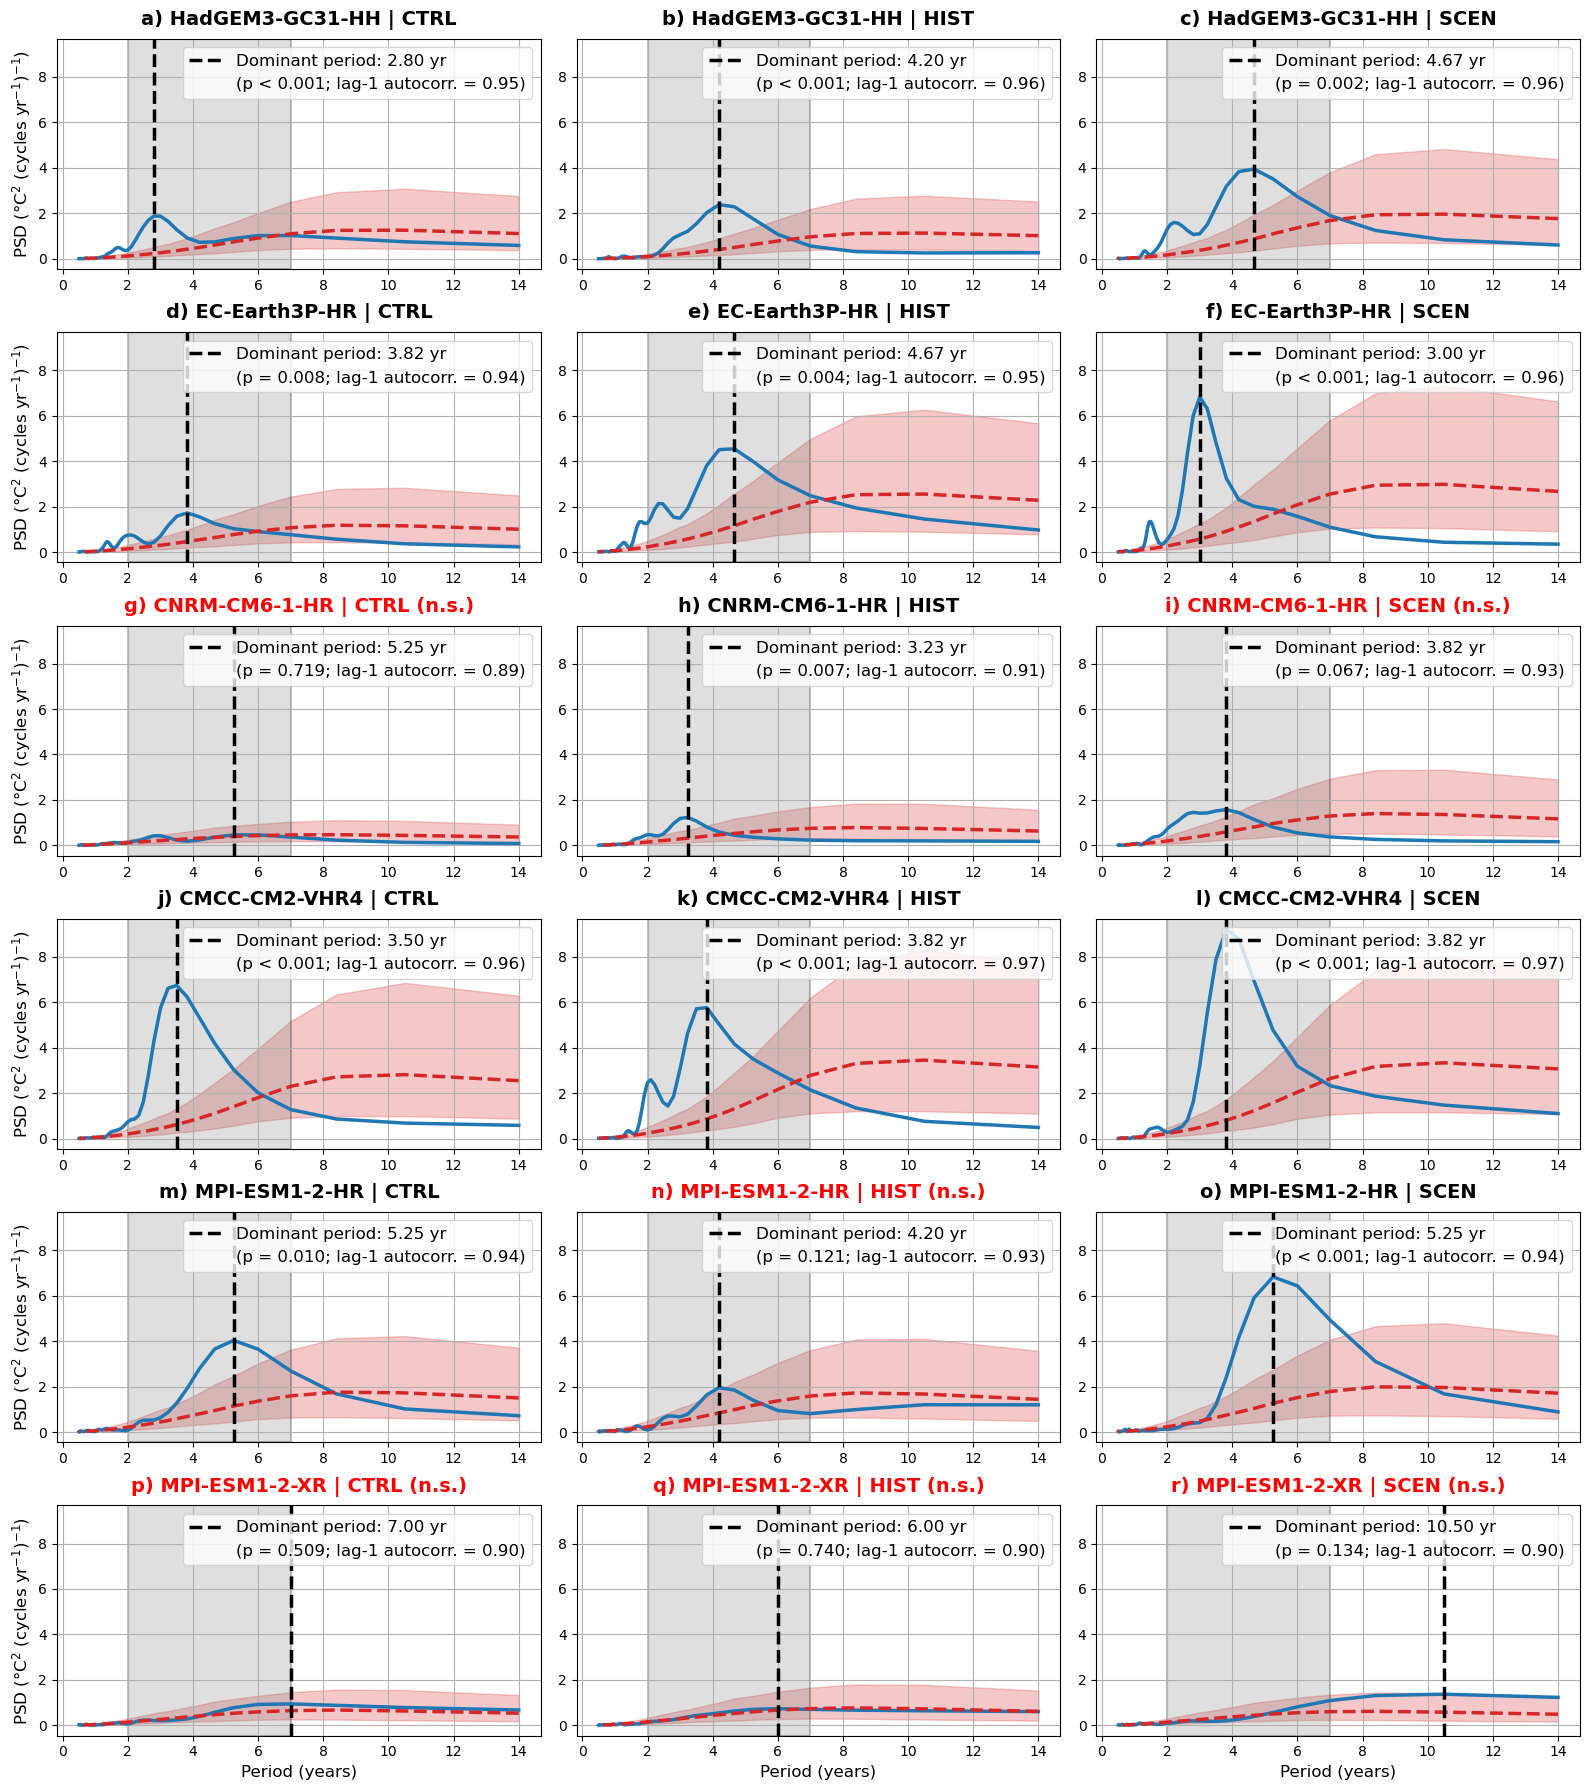

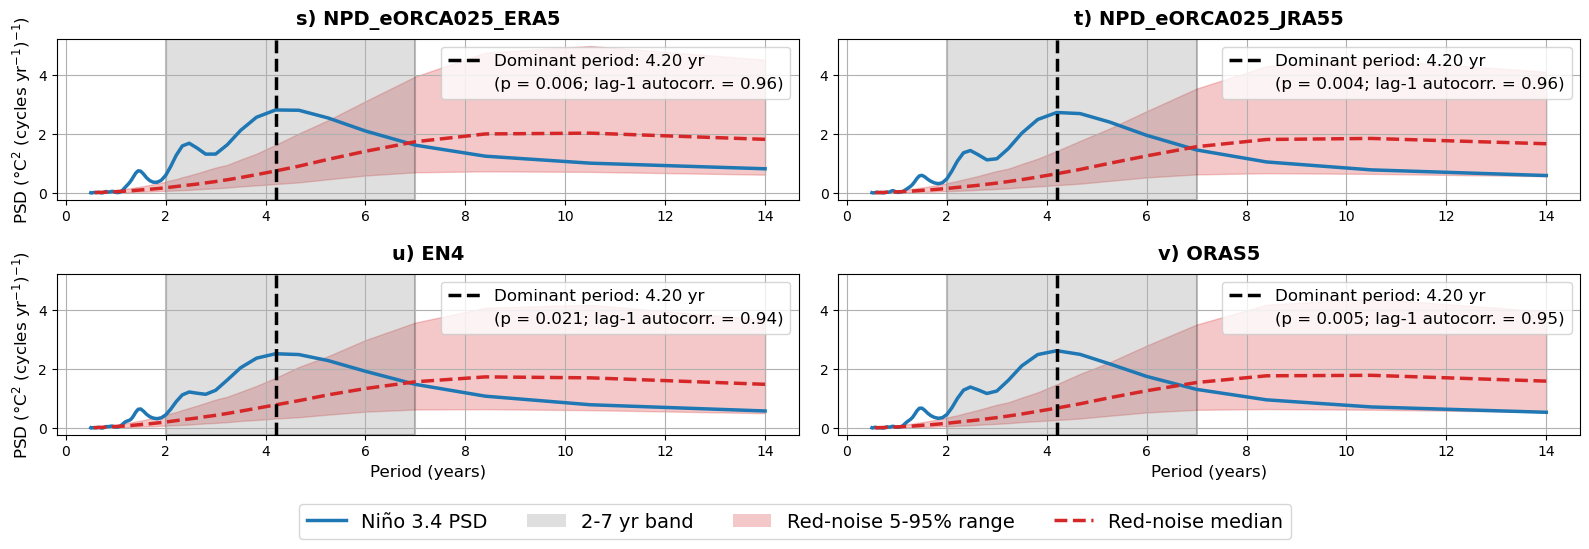

In [7]:
# =============================================================================
# HELPER FUNCTIONS FOR FIGURE C1
# =============================================================================
# Helper function to build a panel name from a dataset key
def panel_name(col):
    """
    Build a panel name from a dataset key, e.g. 'HadGEM3-GC31-HH_CTRL' ==>> 'HadGEM3-GC31-HH | CTRL'.
    """
    model, _, exp = col.rpartition('_')
    return f'{model} | {exp}' if exp in ('CTRL', 'HIST', 'SCEN') else col

# Helper function to plot one panel of FIGURE C1 (shared by PART 1 and PART 2): a dataset's Welch PSD against its red-noise envelope
def plot_red_noise_panel(ax, col, panel_label):
    """
    Plot one panel of FIGURE C1: a dataset's Welch PSD against its red-noise envelope.

    Reads the red-noise test results from the global dict 'res' and the significance level from 'ALPHA'.
    The title is red and marked '(n.s.)' when the dominant peak is not significant.

    Parameters
    ----------
    ax (matplotlib.axes.Axes) : Axis to plot on.
    col (str)                 : Dataset key in 'res' (HighResMIP experiment, NPD run or OBS product).
    panel_label (str)         : Panel letter shown in the title (a, b, c, ...).
    """
    r = res[col] # Red-noise test results for this dataset
    # Dominant peak is significant if p <= ALPHA
    sig = r['p_peak'] <= ALPHA

    # Welch PSD of the dataset
    ax.plot(r['period'], r['Pxx'], color='C0', lw=2.5) 
    # Red-noise 5-95% envelope
    ax.fill_between(r['period'], r['p05'], r['p95'], color='C3', alpha=0.25)
    # Red-noise median (background)
    ax.plot(r['period'], r['median'], color='C3', lw=2.5, ls='--')
    # ENSO band (2-7 yr)
    ax.axvspan(2.0, 7.0, facecolor='gray', edgecolor='k', alpha=0.25, lw=1.5)
    # Vertical dashed line at the dominant period, with a legend entry that includes the period value
    ax.axvline(r['dominant_period'], color='k', ls='--', lw=2.5, label=f"Dominant period: {r['dominant_period']:.2f} yr")
    # p-value as legend text: values below 0.001 are printed as '< 0.001' (smallest attainable p is 1 / 2001 with 2000 simulations)
    p_text = '< 0.001' if r['p_peak'] < 0.001 else f"= {r['p_peak']:.3f}"
    # Invisible scatter point, only used to add the p-value and lag-1 autocorrelation as a legend entry
    ax.scatter([], [], color='w', alpha=0, label=f"(p {p_text}; lag-1 autocorr. = {r['phi']:.2f})")
    # Title is black when the dominant peak is significant (p <= ALPHA), red with '(n.s.)' otherwise
    ax.set_title(f'{panel_label}) {panel_name(col)}' + ('' if sig else ' (n.s.)'),
                 fontsize=14, fontweight='bold', color='black' if sig else 'red', pad=10)
    # Axis labels only on the bottom row (x) and left column (y) of whichever grid the panel sits in
    ss = ax.get_subplotspec()
    ax.set_xlabel('Period (years)' if ss.is_last_row() else '', fontsize=12)
    ax.set_ylabel(PSD_LABEL if ss.is_first_col() else '', fontsize=12)
    # Tick labels shown on every panel despite the shared axes
    ax.tick_params(left=True, labelleft=True, bottom=True, labelbottom=True)
    ax.grid()
    # Legend: dominant period, p-value and lag-1 autocorrelation
    ax.legend(fontsize=12, loc='upper right', frameon=True)

# =============================================================================
# FIGURE C1 (PART 1): PSD vs RED-NOISE ENVELOPE FOR EACH HIGHRESMIP EXPERIMENT
# =============================================================================
fig, axes = plt.subplots(6, 3, figsize=(16,18), sharey=True, sharex=True) # One row per model; columns = CTRL, HIST, SCEN

# One panel per HighResMIP experiment (same layout as FIGURE 2i), labelled a, b, c, ...
for label, ax, col in tqdm(zip(string.ascii_lowercase, axes.flatten(), HIGHRESMIP_EXPS), desc='Processing datasets'):
    plot_red_noise_panel(ax, col, label)
fig.tight_layout(h_pad=0.75, w_pad=1.25)
fig.savefig(f'{FIG_DIR}figure_C1_pt1.png', bbox_inches = 'tight', dpi = 300)

# =============================================================================
# FIGURE C1 (PART 2): PSD vs RED-NOISE ENVELOPE FOR THE NPD RUNS AND OBS DATASETS
# =============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16,5), sharey=True, sharex=True)

# NPD runs and OBS products in a 2 x 2 grid; panel labels continue from PART 1
for label, ax, col in tqdm(zip(string.ascii_lowercase[len(HIGHRESMIP_EXPS):], axes.flatten(), NPD_EXPS + OBS), desc='Processing datasets'):
    plot_red_noise_panel(ax, col, label)
fig.tight_layout(h_pad=1.5, w_pad=1.5)

# Shared figure legend (proxy artists), placed below the panels; it describes both parts of FIGURE C1
handles = [
    Line2D([0], [0], color='C0', lw=2.5, label='Niño 3.4 PSD'),
    Patch(facecolor='gray', alpha=0.25, edgecolor='none', label='2-7 yr band'),
    Patch(facecolor='C3', alpha=0.25, edgecolor='none', label='Red-noise 5-95% range'),
    Line2D([0], [0], color='C3', lw=2.5, ls='--', label='Red-noise median'),
]
# Anchored just below the figure's bottom edge, clear of the x-axis labels (bbox_inches='tight' keeps it in the saved file)
fig.legend(handles=handles, loc='upper center', ncol=len(handles), frameon=True, fontsize=14, bbox_to_anchor=(0.5, 0.0))
fig.savefig(f'{FIG_DIR}figure_C1_pt2.png', bbox_inches = 'tight', dpi = 300)

# =============================================================================
# MERGING BOTH FIGURES ABOVE INTO A SINGLE FIGURE
# =============================================================================
merge_pngs_vertical(
    [
        f"{FIG_DIR}figure_C1_pt1.png",
        f"{FIG_DIR}figure_C1_pt2.png",
    ],
    f"{FIG_DIR}figure_C1.png",
)

### Figure C2: Significance of absolute difference in dominant periodicity of the Niño 3.4 SST anomaly timeseries in CMIP6 HighResMIP model simulations (and rel. OBS)

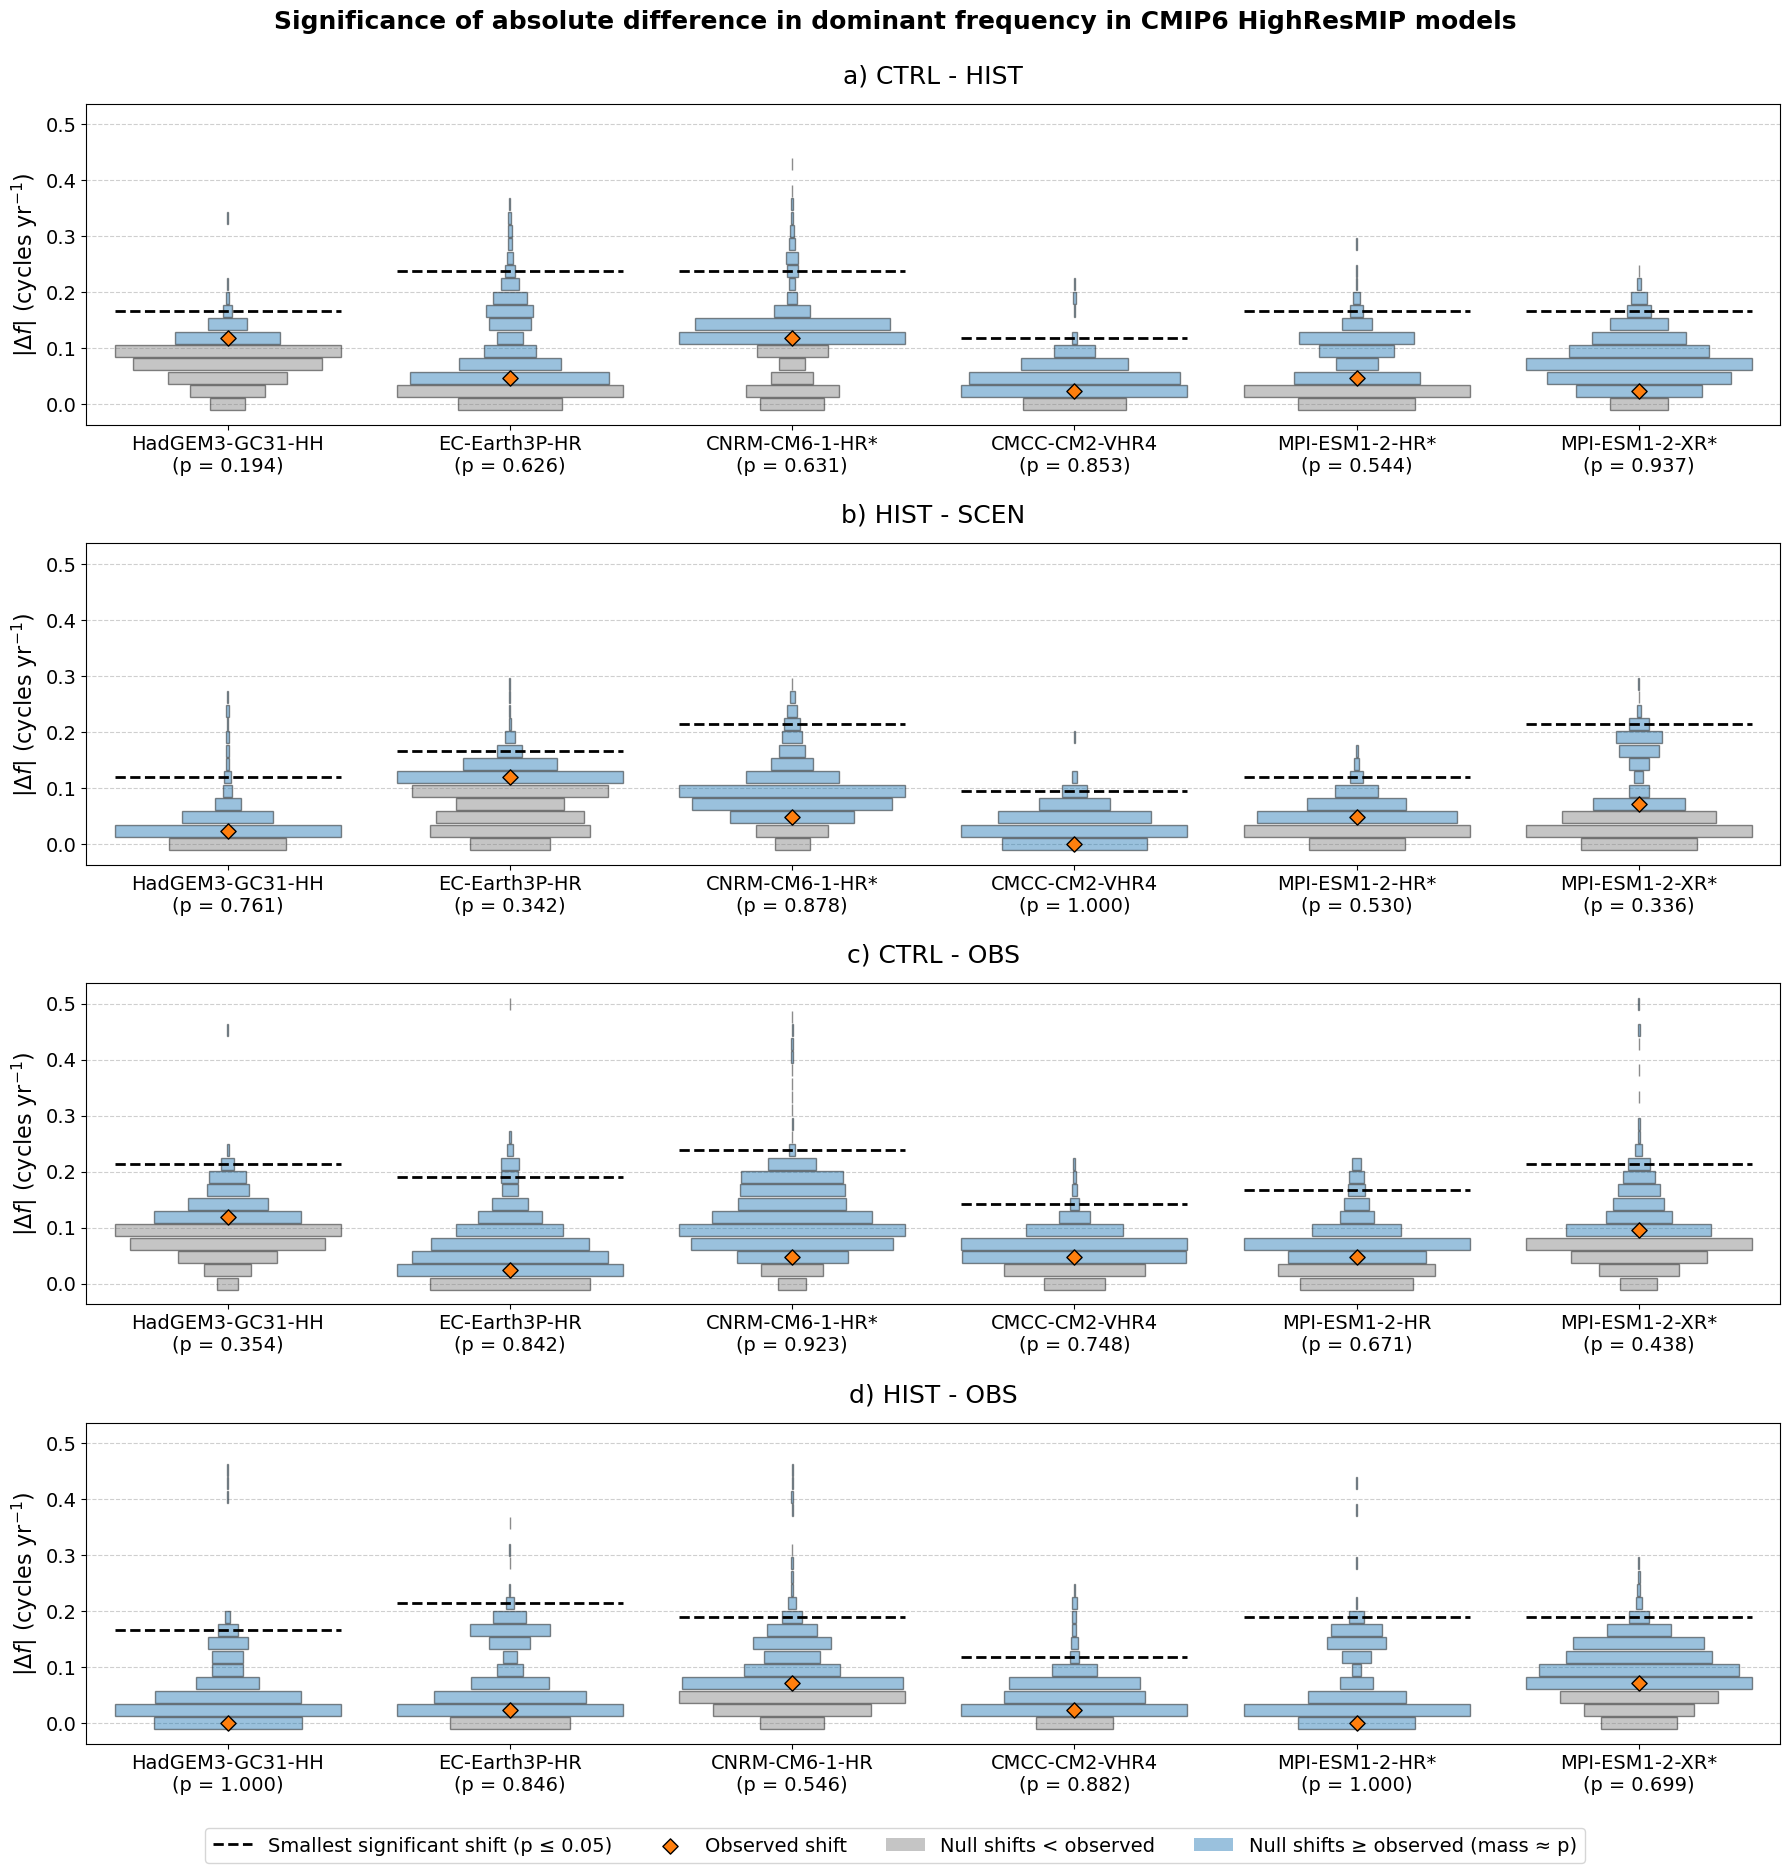

In [8]:
# =============================================================================
# FIGURE C2: NULL DISTRIBUTIONS OF THE DOMINANT-FREQUENCY SHIFT vs OBSERVED SHIFT
# =============================================================================
bar_alpha = 0.45 # Bar transparency
below_color, tail_color = "grey", "C0" # Bar colours: null shifts below / at-or-above the observed shift

# Figure layout: 4 rows (one per shift comparison), 1 column (all models in each row)
fig, axes = plt.subplots(4,1, figsize = (18,18), sharex = False, sharey = True)
axes = axes.flatten()
# One row (axis) per shift comparison, labelled a-d
for label, shift_check_type, ax in zip('abcd', ['CTRL-HIST', 'HIST-SCEN', 'CTRL-OBS', 'HIST-OBS'], axes):
    ticklabels = [] # X-tick labels for this row (one per model)
    for i, model in enumerate(HIGHRESMIP_MODELS): # One null distribution per model
        # Pre-computed shift-test results for this model and comparison: the *_bins entries are in whole grid steps of DF,
        # the matching *_cpy / null_dist entries in cycles/yr (shift = observed, crit = critical, null = null distribution)
        st = shift_test_dict[(model, shift_check_type)] 

        # The null takes only whole numbers of grid steps (DF = 1/42 cycles/yr), so it is drawn
        # as a horizontal histogram ('violin' of bars) centred on x = i, one bar per attainable shift
        k_vals, counts = np.unique(st['null_bins'], return_counts=True)
        half = 0.40 * counts / counts.max() # width proportional to frequency

        # Bars at or above the observed shift are coloured: their total mass is ~ the p-value
        in_tail = k_vals >= st['shift_bins']
        ax.barh(k_vals * DF, 2 * half, left=i - half, height=0.9 * DF, color=np.where(in_tail, tail_color, below_color),
                alpha=bar_alpha, edgecolor="k", zorder=1)

        # Critical shift: the smallest shift that would give p <= ALPHA (computed in shift_test)
        ax.hlines(st['crit_cpy'], i - 0.4, i + 0.4, color="k", lw=2, ls="--", zorder=3,
                  label=f"Smallest significant shift (p ≤ {ALPHA})" if i == 0 else None)

        # Observed shift (diamond marker, labelled once for the legend)
        ax.scatter(i, st['shift_cpy'], marker="D", s=60, color="tab:orange", edgecolor="k",
                   zorder=3, label="Observed shift" if i == 0 else None)

        # '*' after the model name: at least one of the two series in this comparison has no significant dominant peak
        # in the red-noise test (p_peak > ALPHA; red '(n.s.)' panels in FIGURE C1). The shift test is still run and its
        # p-value shown, but the shift is not interpreted. Explain the '*' in the figure caption
        star = '' if st['both_peaks_sig'] else '*'
        # X-tick label: model name (+ '*') and the p-value of the shift test (values below 0.001 are printed as '< 0.001')
        p_text = '< 0.001' if st['p_value'] < 0.001 else f"= {st['p_value']:.3f}"
        ticklabels += [f"{model}{star}\n(p {p_text})"]

    # Axis styling: one x tick per model, labelled with its p-value
    ax.set_xticks(range(len(HIGHRESMIP_MODELS)))
    ax.set_xticklabels(ticklabels, fontsize=14)
    ax.set_ylabel(SHIFT_LABEL, fontsize=16)
    ax.set_xlim([-0.5, len(HIGHRESMIP_MODELS) - 0.5])
    ax.tick_params(axis = 'both', labelsize = 14)
    ax.grid(axis="y", linestyle="--", alpha=0.6)
    ax.set_axisbelow(True)
    # Row title: panel label and shift comparison
    ax.set_title(f"{label}) {shift_check_type.replace('-', ' - ')}", fontsize=18, pad=15)
# Shared figure title
fig.suptitle('Significance of absolute difference in dominant frequency in CMIP6 HighResMIP models', fontsize=18, fontweight="bold", y = 1.00)

# Adding a legend: existing entries (critical shift, observed shift) + proxy patches for the bar shading
handles, _ = ax.get_legend_handles_labels()
handles += [Patch(facecolor=below_color, alpha=bar_alpha, label="Null shifts < observed"),
            Patch(facecolor=tail_color, alpha=bar_alpha, label="Null shifts ≥ observed (mass ≈ p)")]
fig.legend(handles=handles, loc = 'lower center', fontsize = 14, frameon = True, ncols = 4, bbox_to_anchor=(0.5, -0.035))

fig.tight_layout(h_pad=2.0, w_pad=2.0)
fig.savefig(f'{FIG_DIR}figure_C2.png', bbox_inches = 'tight', dpi = 300)

### Figure C3 & C4: SST anomaly composites of ENSO events in models and observations for the historical (1979-2014) and future (2015-2050) periods.

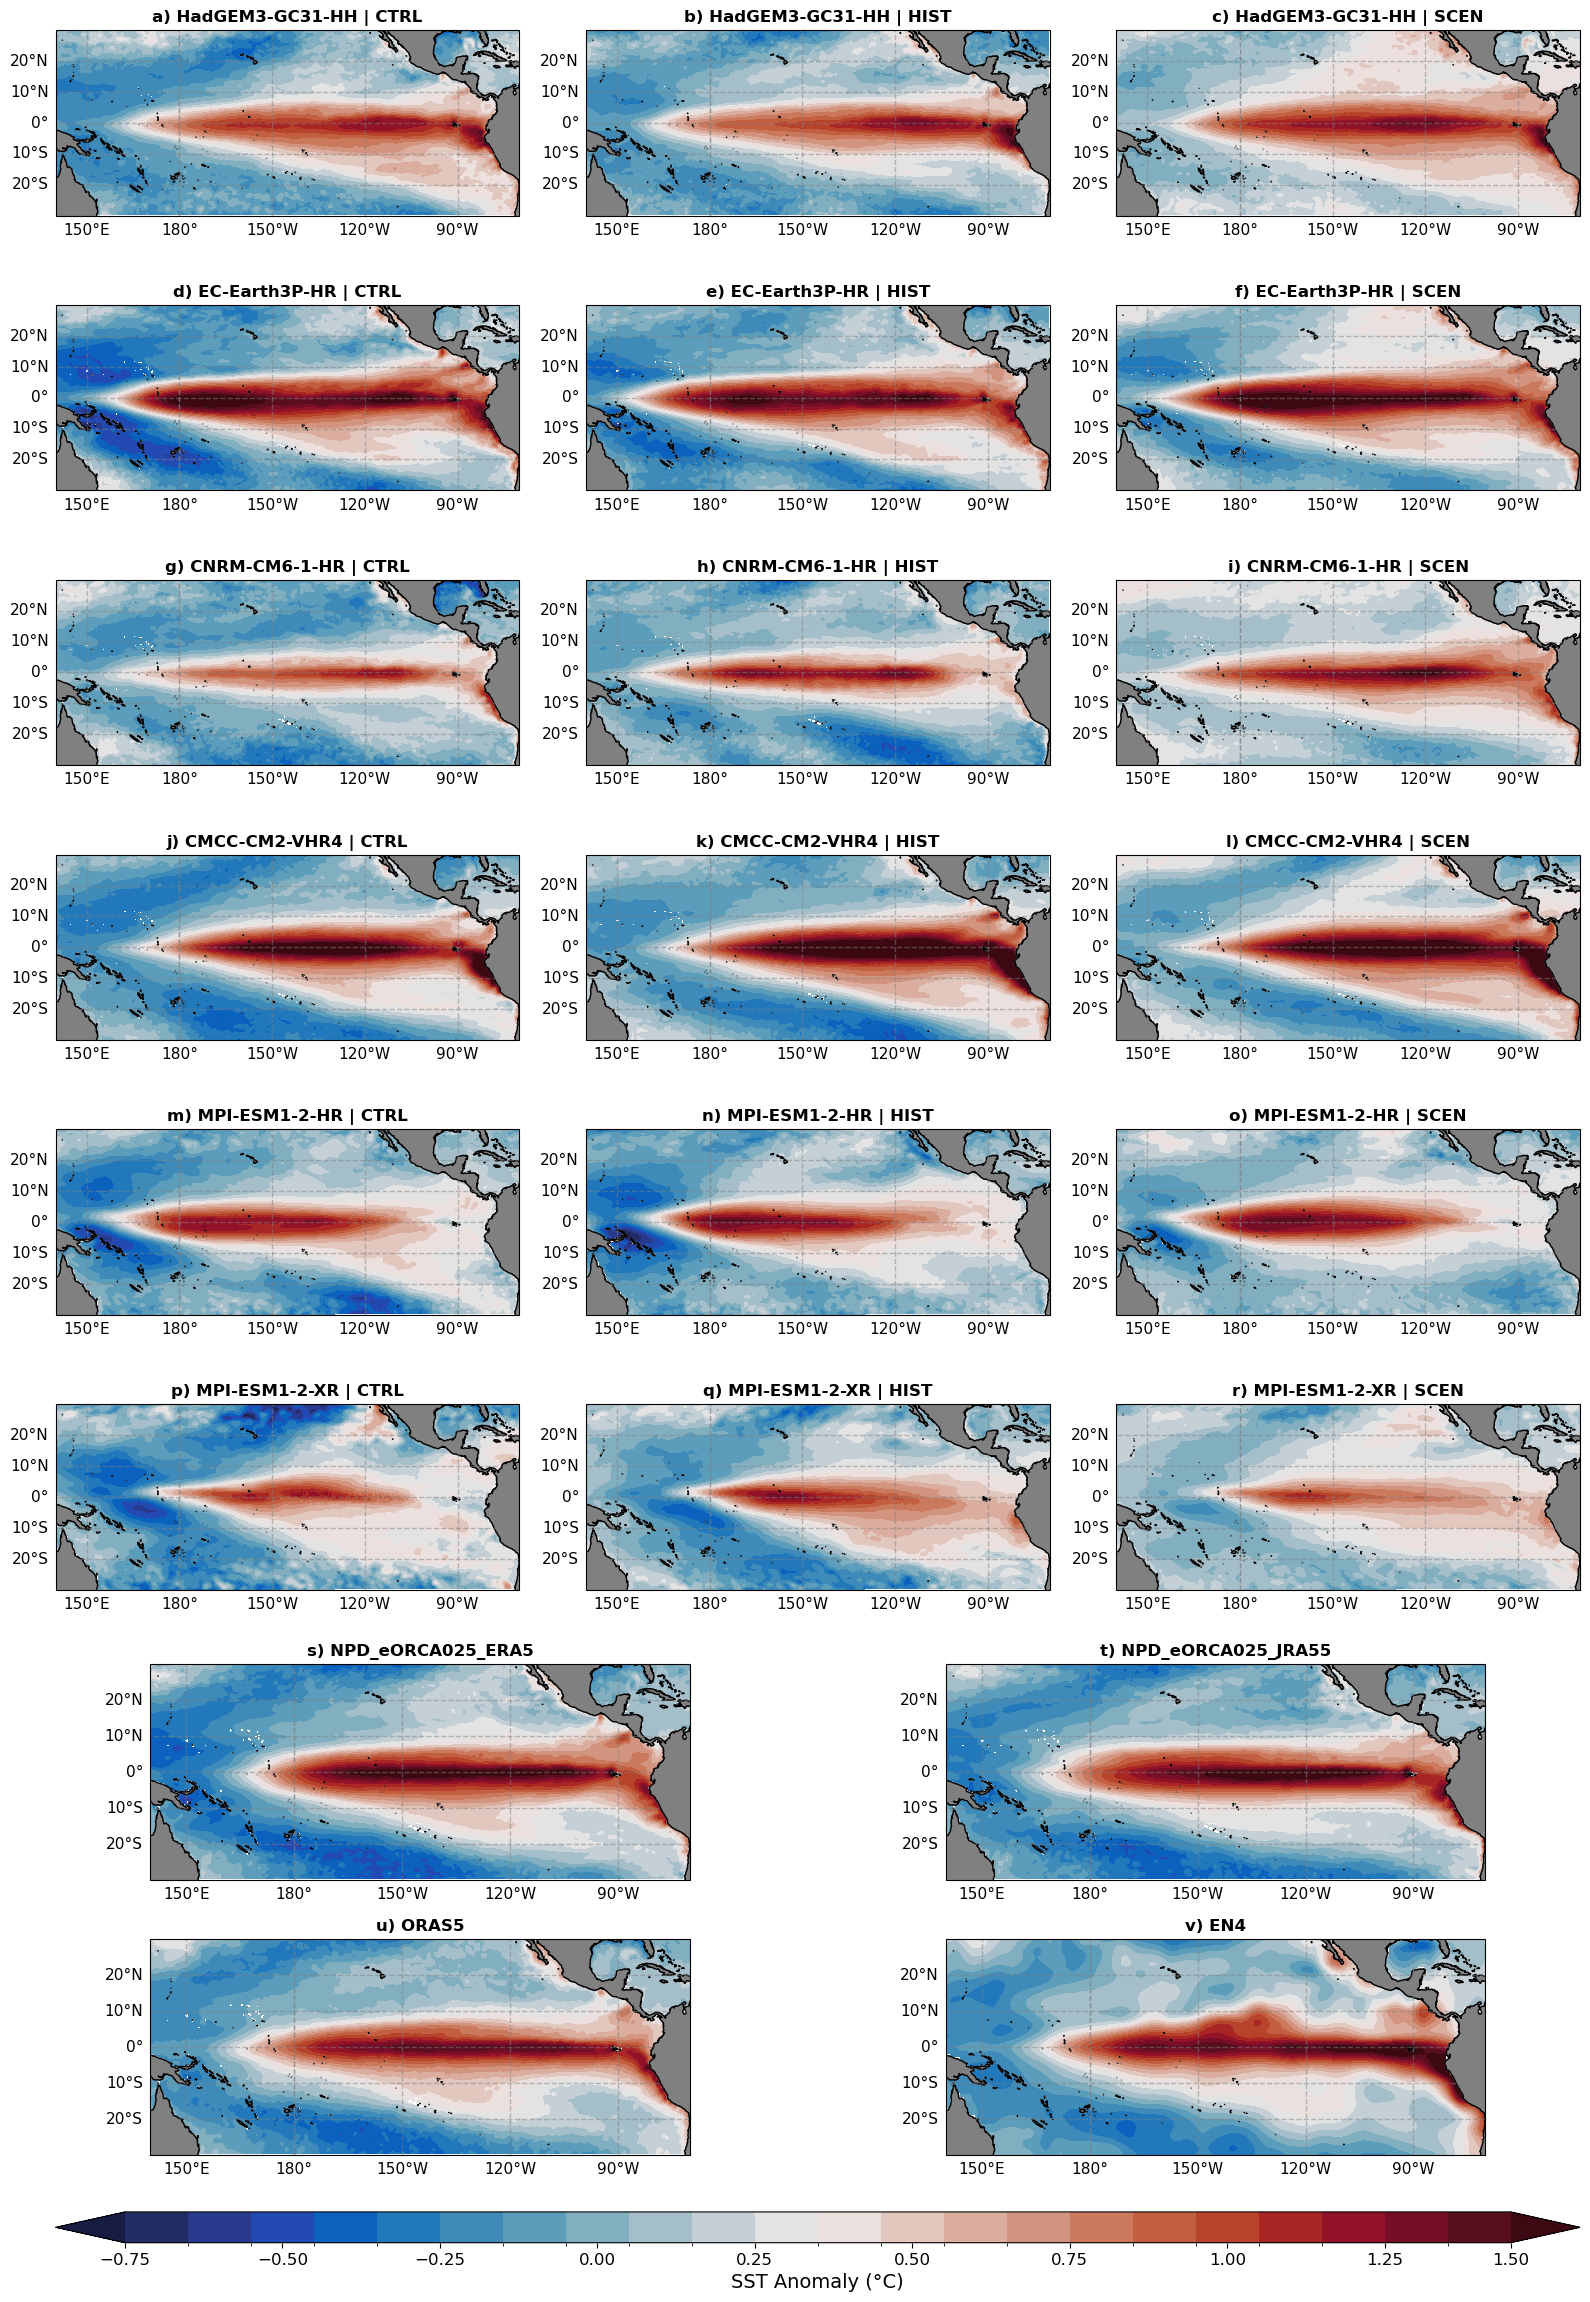

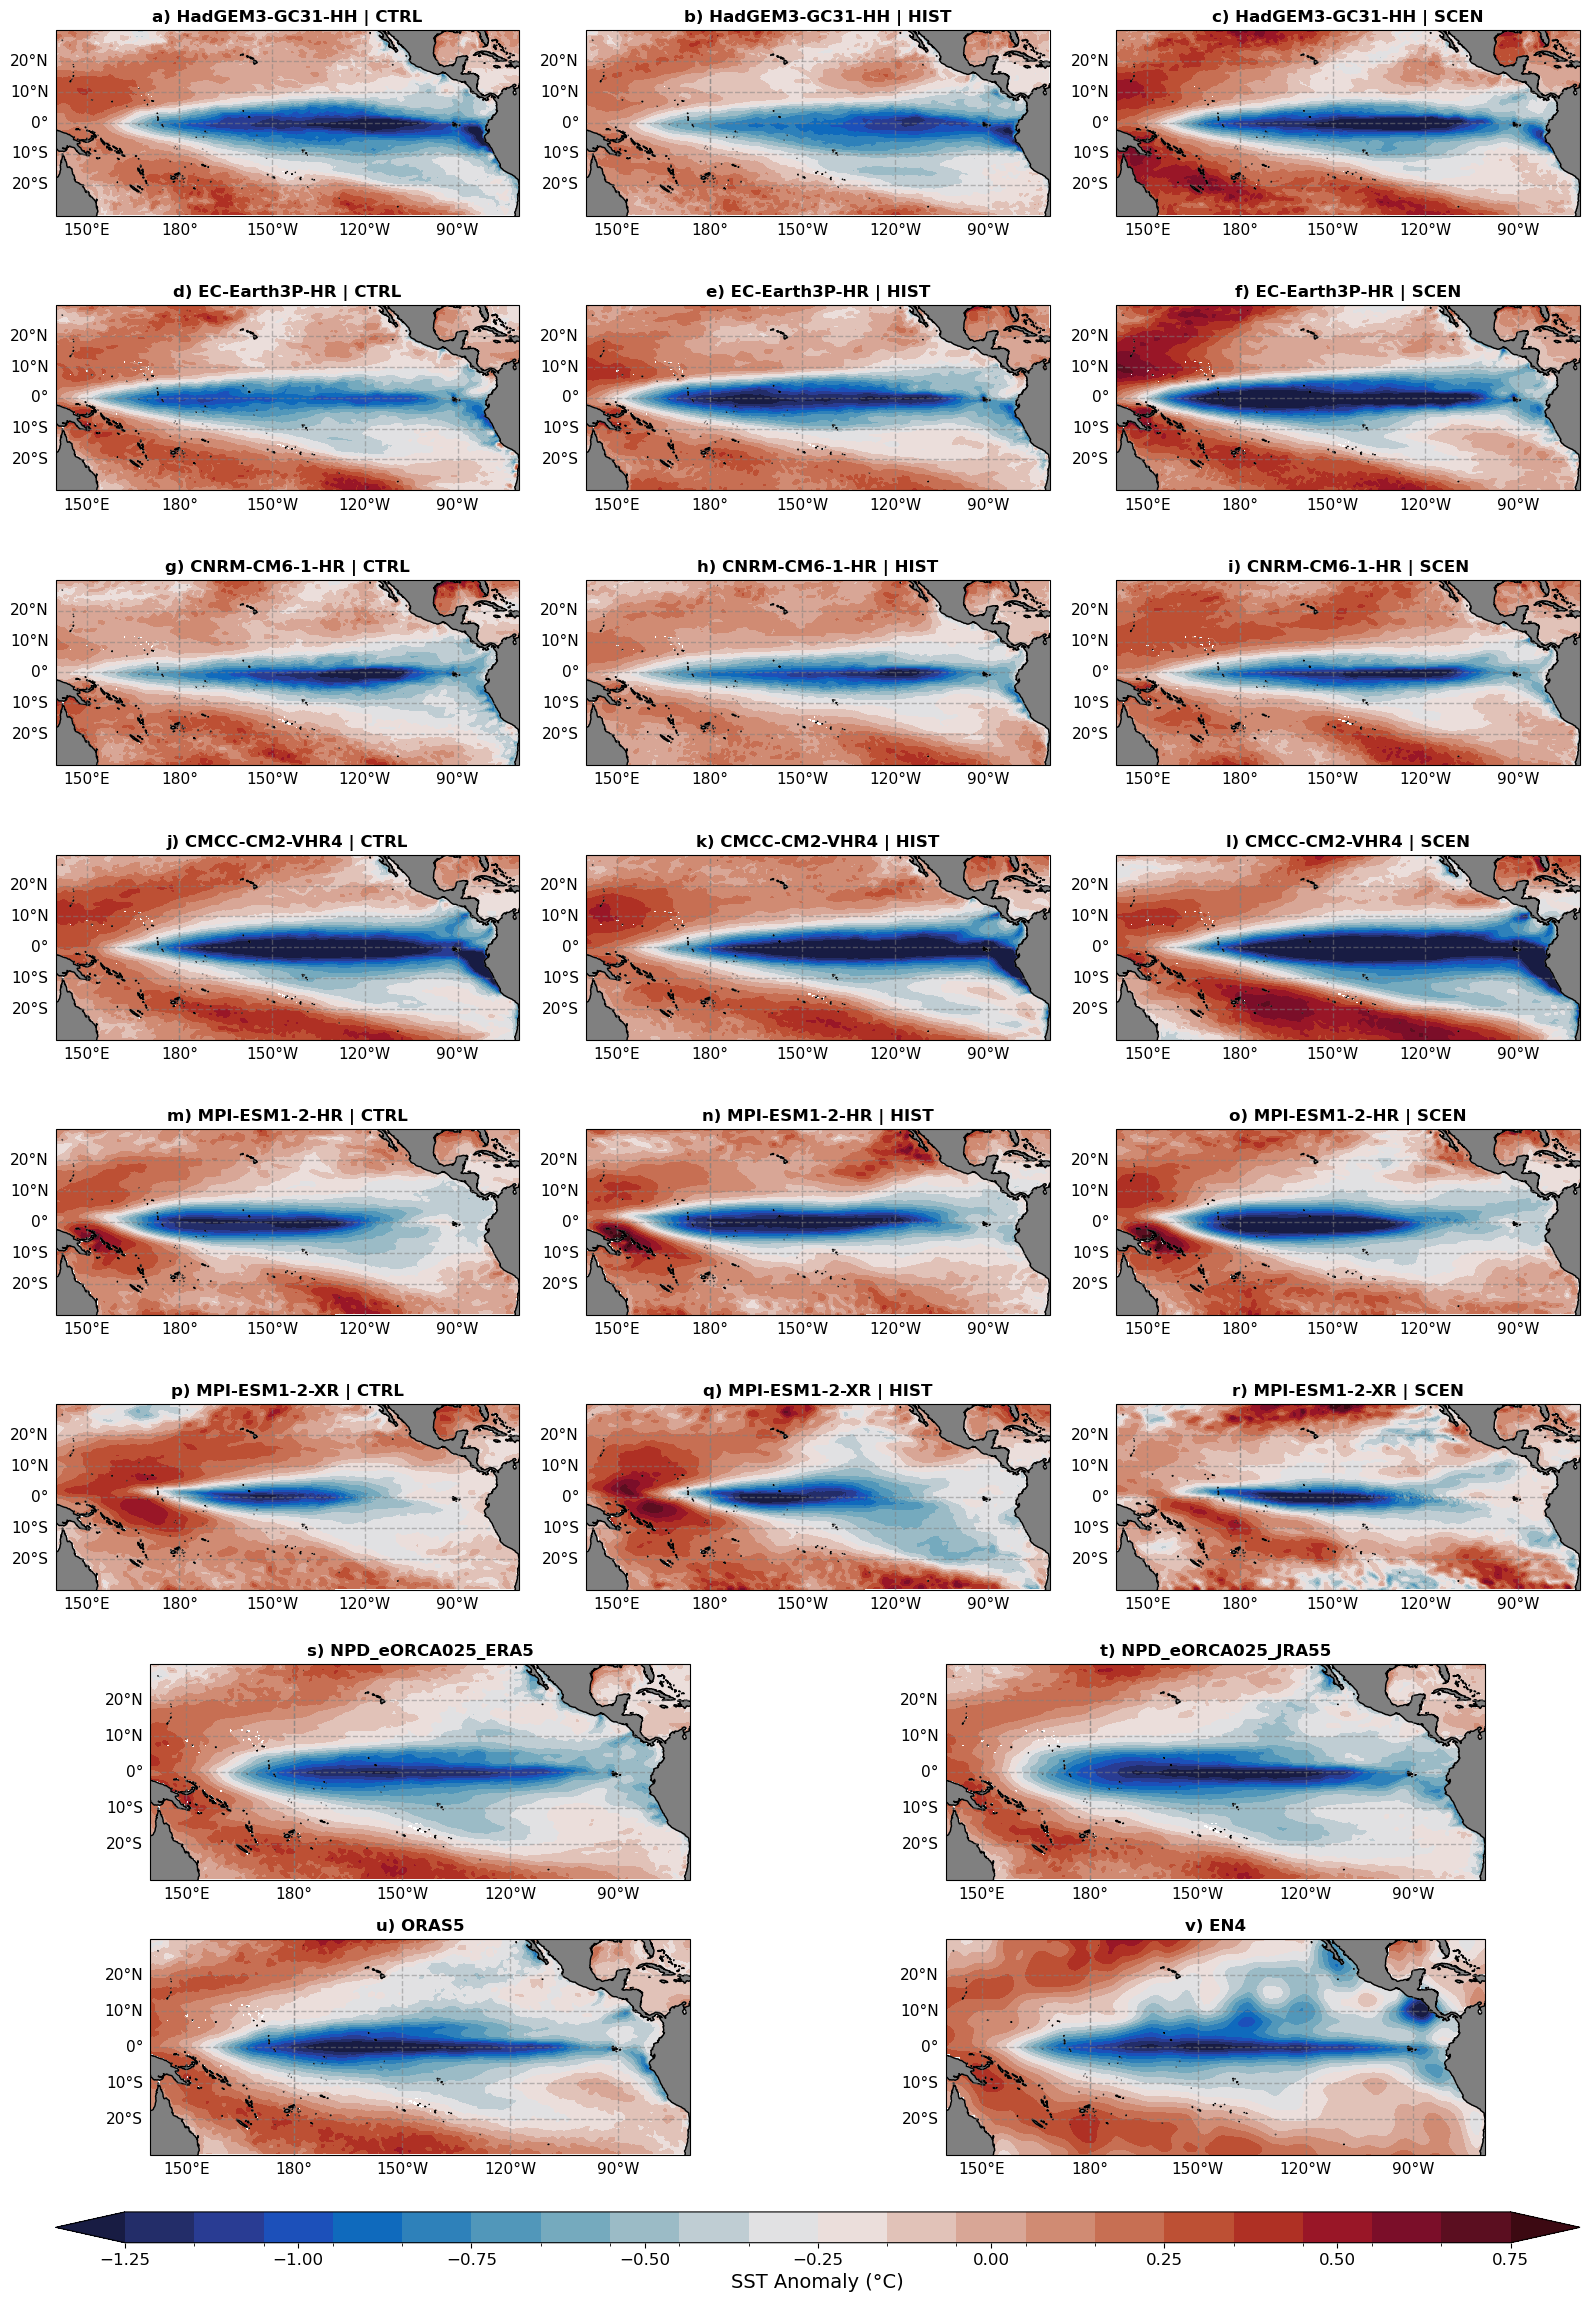

In [11]:
# =============================================================================
# READING IN THE PER-DATASET ENSO SSTA COMPOSITES (BOTH PERIODS)
# =============================================================================
# CTRL/HIST runs (and NPD/OBS) come from the HIST_EVAL files, SCEN runs from the FUTR_EVAL files. Each file holds one
# dataset and only its surface level is kept, so every file is read once and reused for both ENSO phases
composites = {}
for dataset_name, _, _, _, exp in PANEL_SPECS:
    period_label = 'FUTR_EVAL_2015-2050' if exp == 'SCEN' else 'HIST_EVAL_1979-2014'
    with xr.open_dataset(f'{DATA_DIR}ENSO_TEMPANOM_COMPOSITES/ENSO_TEMPANOM_COMPOSITES_{dataset_name}_{period_label}.nc') as ds:
        composites[dataset_name] = ds.sel(depth = 0, method = 'nearest').load()

# =============================================================================
# FIGURE C3 & C4: PER-DATASET ENSO SSTA COMPOSITES (CTRL/HIST/SCEN, + OBS + NPD)
# =============================================================================
# Figure ID and contour range (°C) of each ENSO phase: the colour range differs by phase
COMP_PHASES = {'EL-NINO': {'fig_id': 'C3', 'range': (-0.75, 1.5)},
               'LA-NINA': {'fig_id': 'C4', 'range': (-1.25, 0.75)}}

# Pacific-centred map projection (180°E) and the coordinate system of the data (plain lon/lat)
projection = ccrs.PlateCarree(central_longitude = 180)
transform  = ccrs.PlateCarree()

# Loop over the two ENSO phases (El Niño and La Niña) to create two separate figures (C3 and C4)
for phase, cfg in COMP_PHASES.items():
    # Contour levels and colorbar ticks
    lo, hi = cfg['range']
    levels_enso_comp = np.arange(lo, hi + 0.001, 0.1)
    ticks_enso_comp  = np.arange(lo, hi + 0.001, 0.25)

    # 8 x 6 grid (see PANEL_SPECS)
    fig = plt.figure(figsize = (16, 22))
    gs  = fig.add_gridspec(8, 6)
    axes = []

    # One panel per dataset, labelled a, b, c, ...
    for label, (dataset_name, title, row, cols, _) in zip(string.ascii_lowercase, PANEL_SPECS):
        ax = fig.add_subplot(gs[row, cols], projection = projection)
        # Composite of this ENSO phase, averaged over its events
        ds = composites[dataset_name]
        ds = ds.where(ds['event_type'] == phase, drop = True).mean(dim = 'event_id')
        da = ds['event_level_composite'].sel(dataset = dataset_name)
        # Filled-contour map of the composite (colorbar is added once, below all panels)
        cbar = da.plot.contourf(ax = ax, transform = transform, x = 'lon', y = 'lat',
                                cmap = cmocean.cm.balance, add_colorbar = False,
                                levels = levels_enso_comp, extend = 'both')
        format_axis(ax = ax, kind = 'map', land_ft = land_50m, coast_ft = coast_50m)
        ax.set_title(f'{label}) {title}', fontsize = 12, fontweight = 'bold')
        axes.append(ax)

    # Layout and shared colorbar
    fig.tight_layout(h_pad = 1.2, w_pad = 1.5)
    # Shared colorbar below all panels
    add_colorbar(fig, axes = np.array(axes), mappable = cbar, label = 'SST Anomaly (°C)',
                 ticks = ticks_enso_comp, side = 'bottom', height = 0.014, pad = 0.04,
                 labelsize = 14, ticksize = 12)
    fig.savefig(f"{FIG_DIR}figure_{cfg['fig_id']}.png", bbox_inches = 'tight', dpi = 300)

### Figure C5: ENSO Regime Proportions - Per Model Simulations, in Historical and Future Evaluation Periods

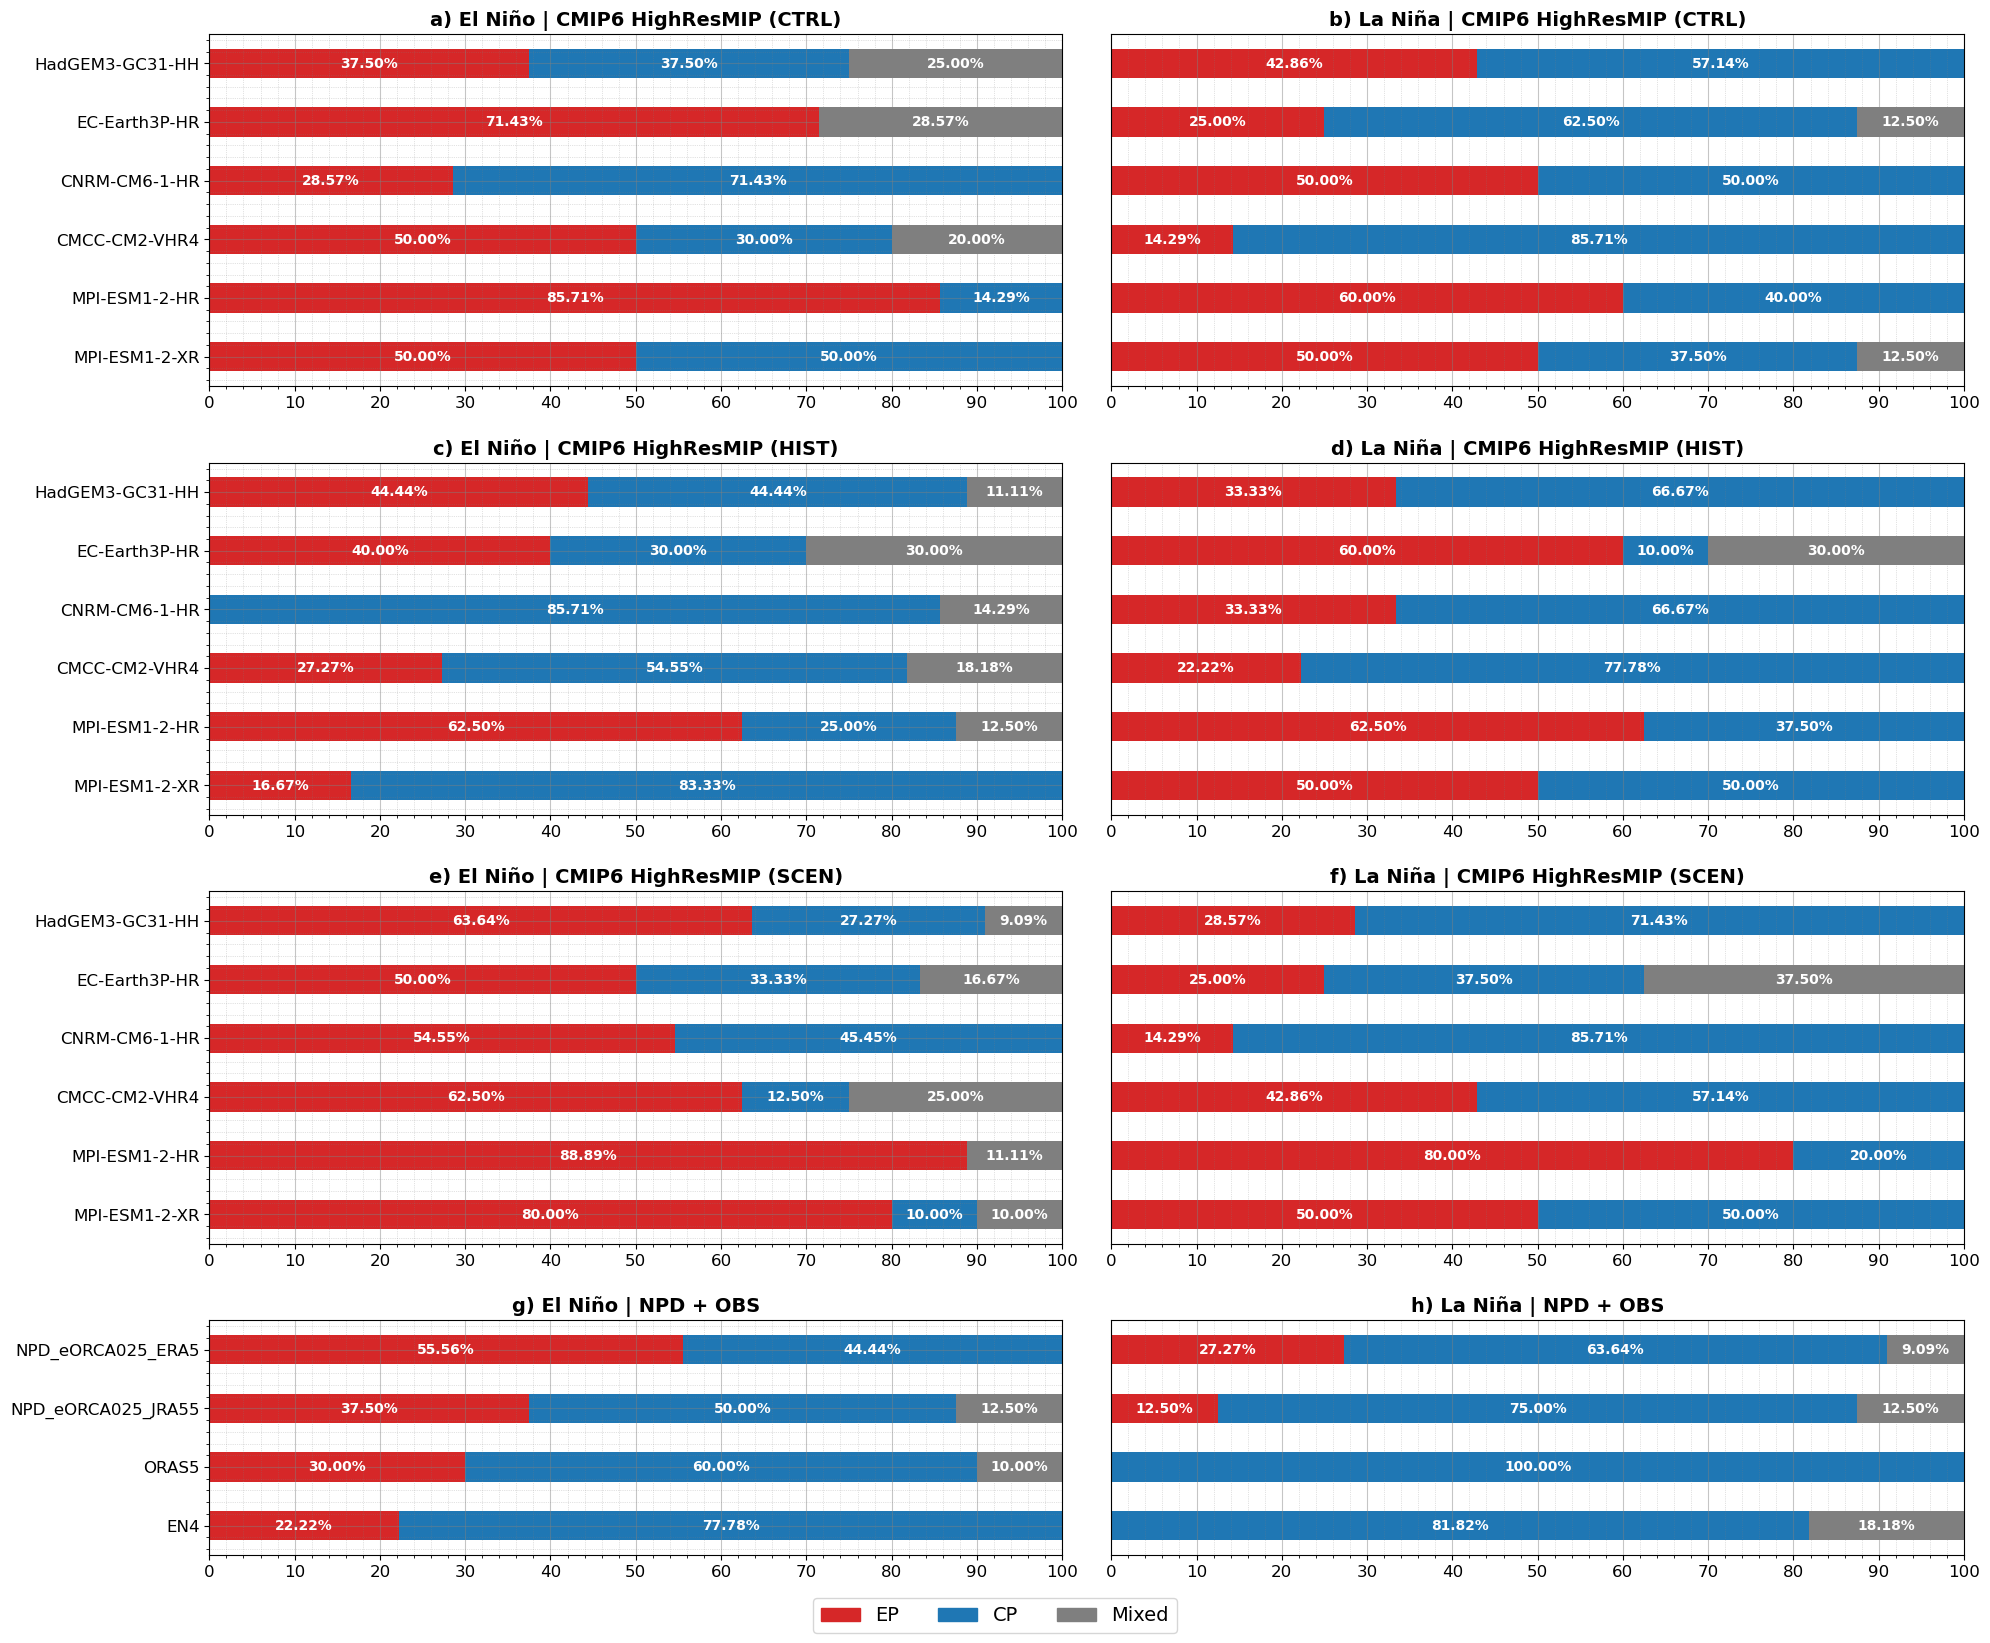

In [12]:
# =============================================================================
# READING IN ENSO FLAVOUR PROPORTIONS (BOTH EVAL PERIODS) AND COMBINING
# =============================================================================
# CTRL/HIST (+ NPD/OBS) come from the HIST_EVAL table; SCEN from the FUTR_EVAL table
enso_flav_prop_HIST = pd.read_csv(f'{DATA_DIR}ENSO_FLAVOUR_PROPORTIONS_HIST_EVAL_1979-2014.csv', index_col = 0)
enso_flav_prop_SCEN = pd.read_csv(f'{DATA_DIR}ENSO_FLAVOUR_PROPORTIONS_FUTR_EVAL_2015-2050.csv', index_col = 0)
# Combined table: one row per dataset, covering both evaluation periods
enso_flav_prop = pd.concat([enso_flav_prop_HIST, enso_flav_prop_SCEN], axis = 0)

# =============================================================================
# FIGURE C5: ENSO FLAVOUR PROPORTIONS (EP/CP/MIXED) FOR EL NIÑO AND LA NIÑA
# =============================================================================
df = enso_flav_prop * 100 # Fractions to percentages

# Row groups: each is a block of stacked horizontal bars (left = El Niño, right = La Niña)
# Each row group: (El Niño panel title, La Niña panel title, datasets to plot, y-axis labels)
obs_idx    = BOTTOM_ROWS[0] + BOTTOM_ROWS[1]
row_groups = [(f'El Niño | CMIP6 HighResMIP ({exp})', f'La Niña | CMIP6 HighResMIP ({exp})',
               [f'{m}_{exp}' for m in HIGHRESMIP_MODELS], HIGHRESMIP_MODELS) for exp in EXP_TYPES]
row_groups += [('El Niño | NPD + OBS', 'La Niña | NPD + OBS', obs_idx, obs_idx)]

# Column names of the stacked bars (EP, CP, MIXED) for El Niño and La Niña, and the colour of each flavour
en_cols        = ['EP-EN', 'CP-EN', 'MIXED-EN']
ln_cols        = ['EP-LN', 'CP-LN', 'MIXED-LN']
flavour_colors = {'EP': 'C3', 'CP': 'C0', 'Mixed': 'C7'}


# Helper function to label each stacked-bar segment with its percentage if >= 5%
def annotate_bars(ax):
    """
    Label each stacked-bar segment with its percentage if it is >= 5%.
    """
    for container in ax.containers:
        for bar in container:
            width = bar.get_width()
            if width >= 5:
                cx = bar.get_x() + width / 2
                cy = bar.get_y() + bar.get_height() / 2
                ax.text(cx, cy, f'{width:.2f}%', ha = 'center', va = 'center',
                        fontsize = 10, fontweight = 'bold', color = 'white')

# Setting up the figure with 4 rows (one per row group) and 2 columns (El Niño on the left, La Niña on the right)
fig, axes = plt.subplots(4, 2, figsize = (20, 16), gridspec_kw = {'height_ratios': [6, 6, 6, 4]})

# Panel labels (a-h)
labels = list('abcdefgh')

# One row per row group: stacked bars for El Niño (left) and La Niña (right)
for row, (en_title, ln_title, idx_list, y_labels) in enumerate(row_groups):
    sub = df.loc[idx_list] # Datasets in this row group

    # El Niño (left column)
    sub[en_cols].plot.barh(stacked = True, ax = axes[row, 0], legend = False, color = list(flavour_colors.values()))
    axes[row, 0].set_yticklabels(y_labels, fontsize = 12)
    axes[row, 0].set_title(f'{labels[2 * row]}) {en_title}', fontsize = 14, fontweight = 'bold')
    annotate_bars(axes[row, 0])

    # La Niña (right column)
    sub[ln_cols].plot.barh(stacked = True, ax = axes[row, 1], legend = False, color = list(flavour_colors.values()))
    axes[row, 1].get_yaxis().set_visible(False)
    axes[row, 1].set_title(f'{labels[2 * row + 1]}) {ln_title}', fontsize = 14, fontweight = 'bold')
    annotate_bars(axes[row, 1])

# Common styling for all axes (x-axis spans 0-100% since EP + CP + Mixed sum to 100%)
for ax in axes.flatten():
    ax.invert_yaxis()
    ax.set_xlim([0, 100])
    ax.set_xticks(np.arange(0, 100.1, 10))
    ax.grid(which = 'major', color = 'gray', alpha = 0.45, linewidth = 0.8)
    ax.grid(which = 'minor', color = 'gray', alpha = 0.45, linestyle = ':', linewidth = 0.5)
    ax.minorticks_on()
    ax.tick_params(axis = 'both', which = 'major', labelsize = 12)

# Shared legend for the stacked bars, placed below the figure
legend_handles = [Patch(color = color, label = flavour) for flavour, color in flavour_colors.items()]
fig.legend(handles = legend_handles, loc = 'lower center', fontsize = 14, ncols = 3, bbox_to_anchor = (0.5, -0.03))

fig.tight_layout(h_pad = 2, w_pad = 2)
fig.savefig(f'{FIG_DIR}figure_C5.png', bbox_inches = 'tight', dpi = 300)

### Figure C6 & C7: KDE of the location of peak |SSTA| during El Niño and La Niña months in models and obs. for the historical (1979-2014) and future evaluation periods (2015-2050)

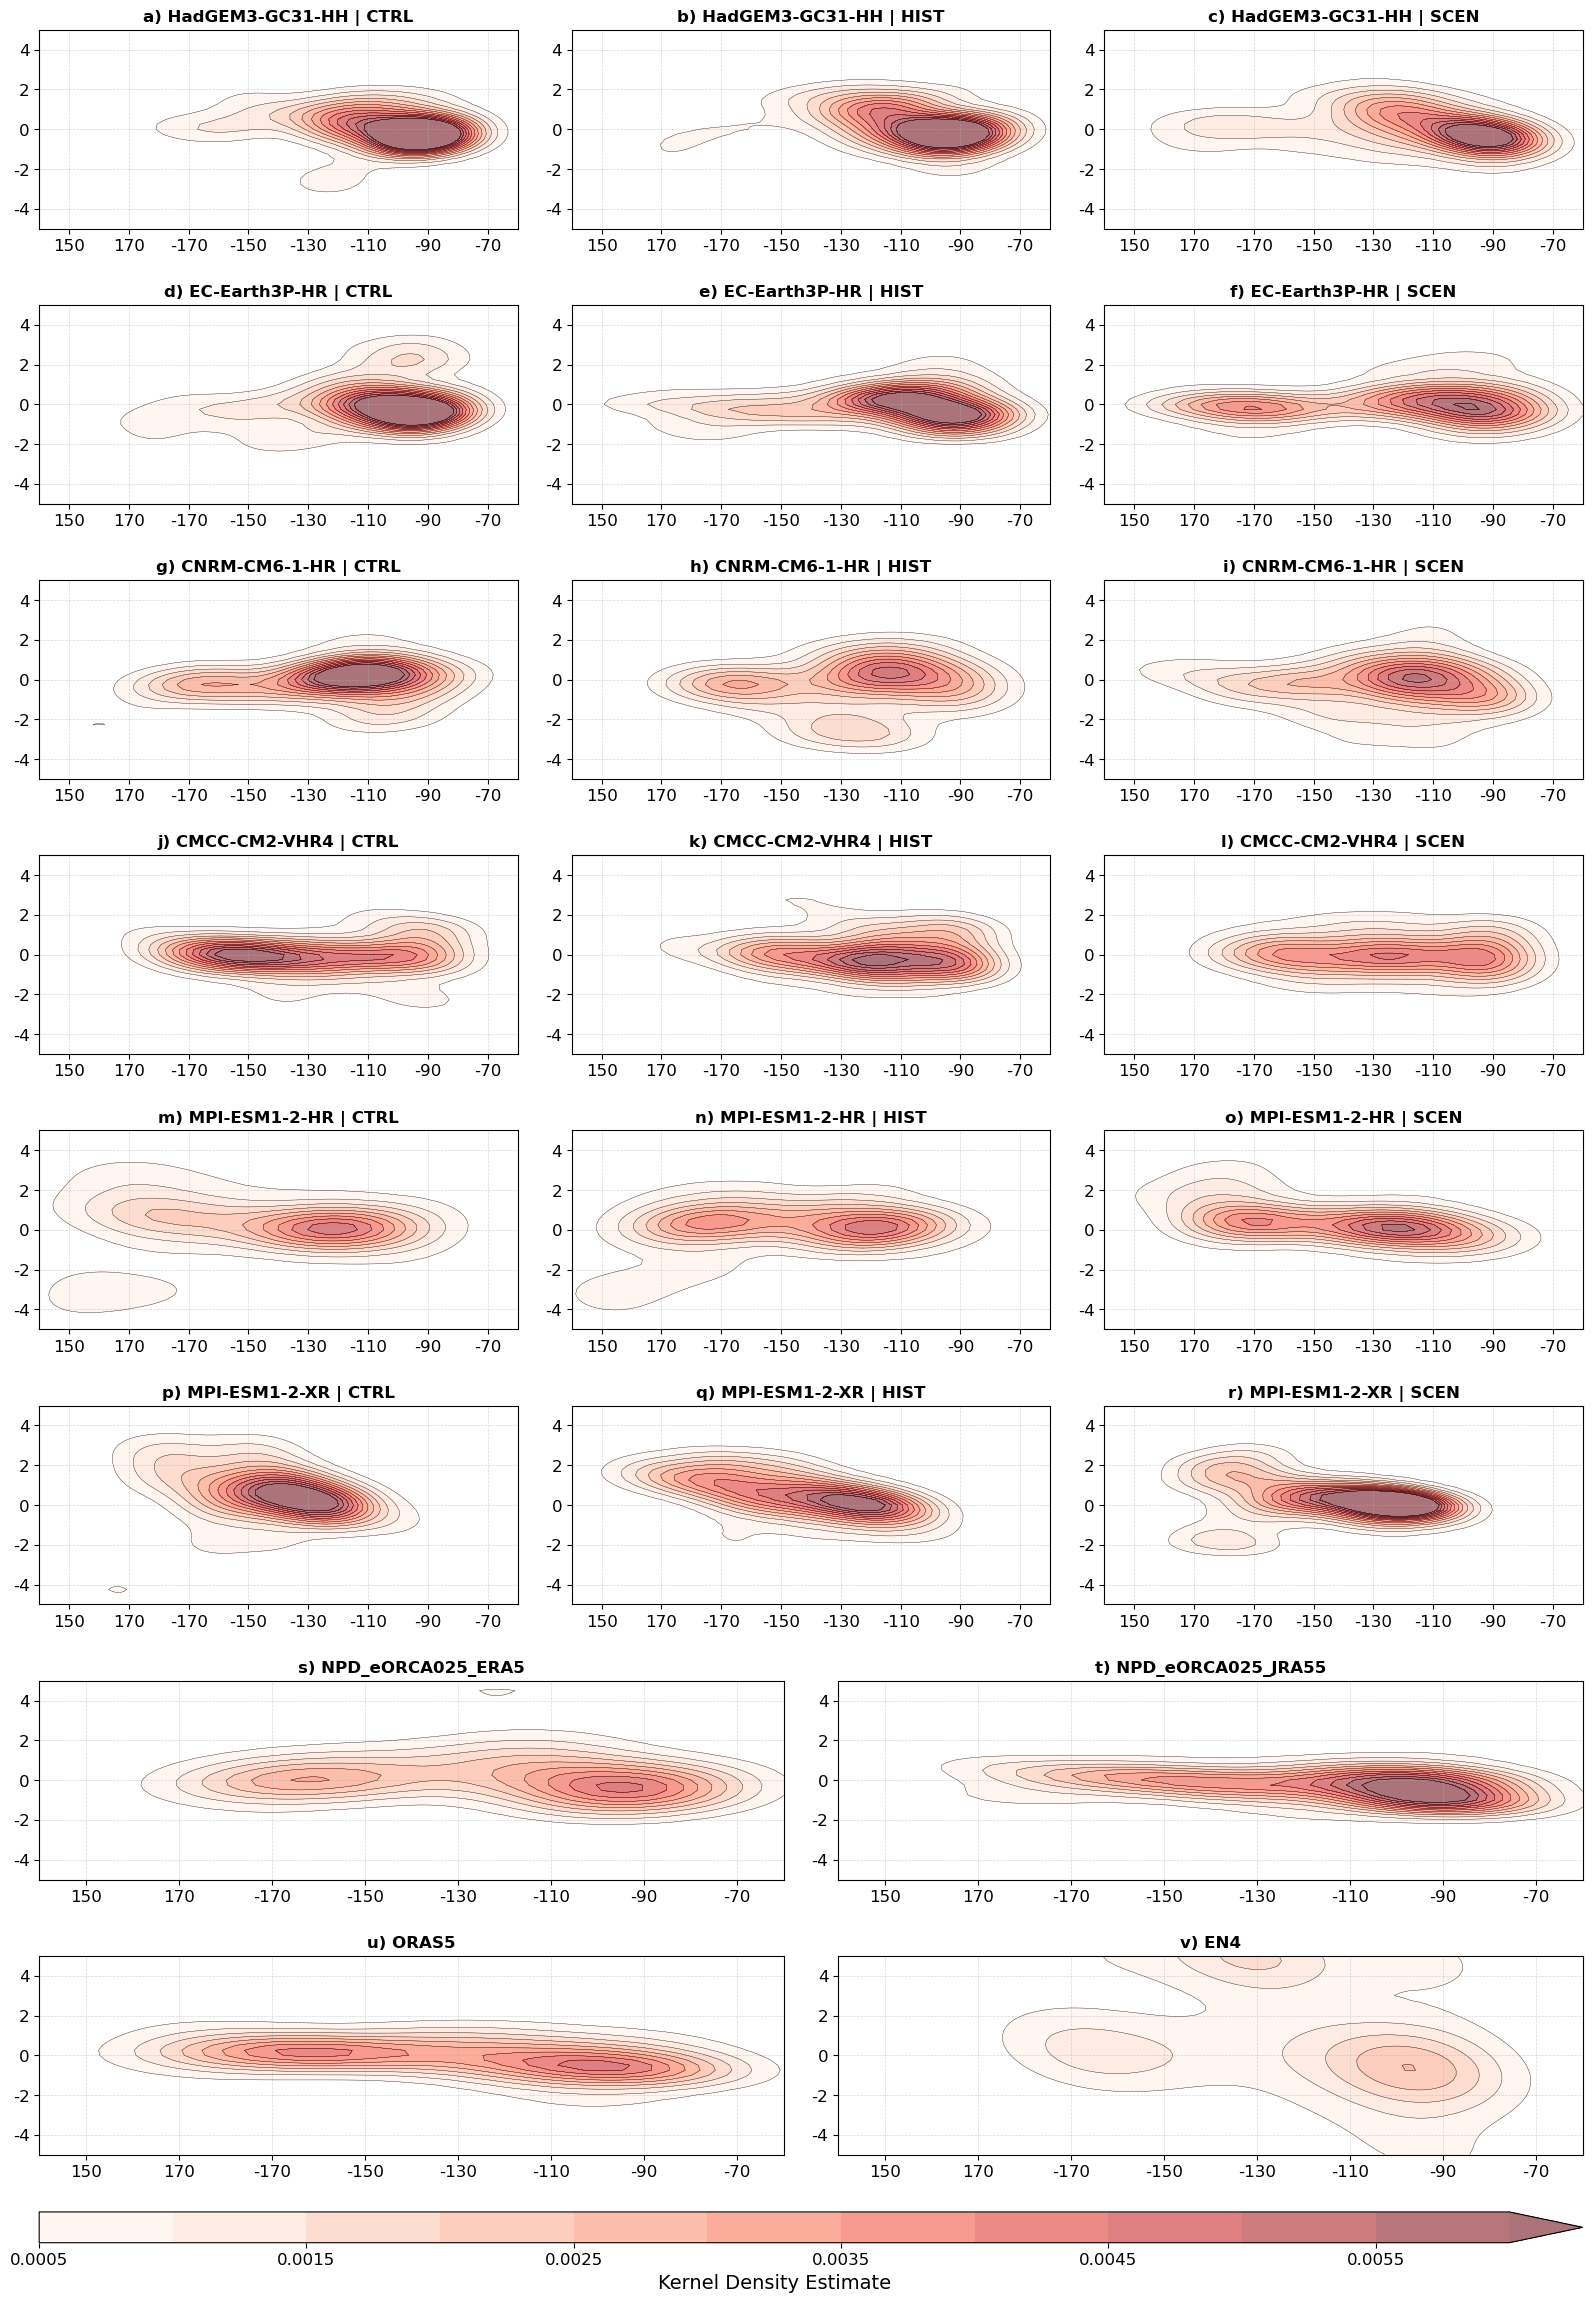

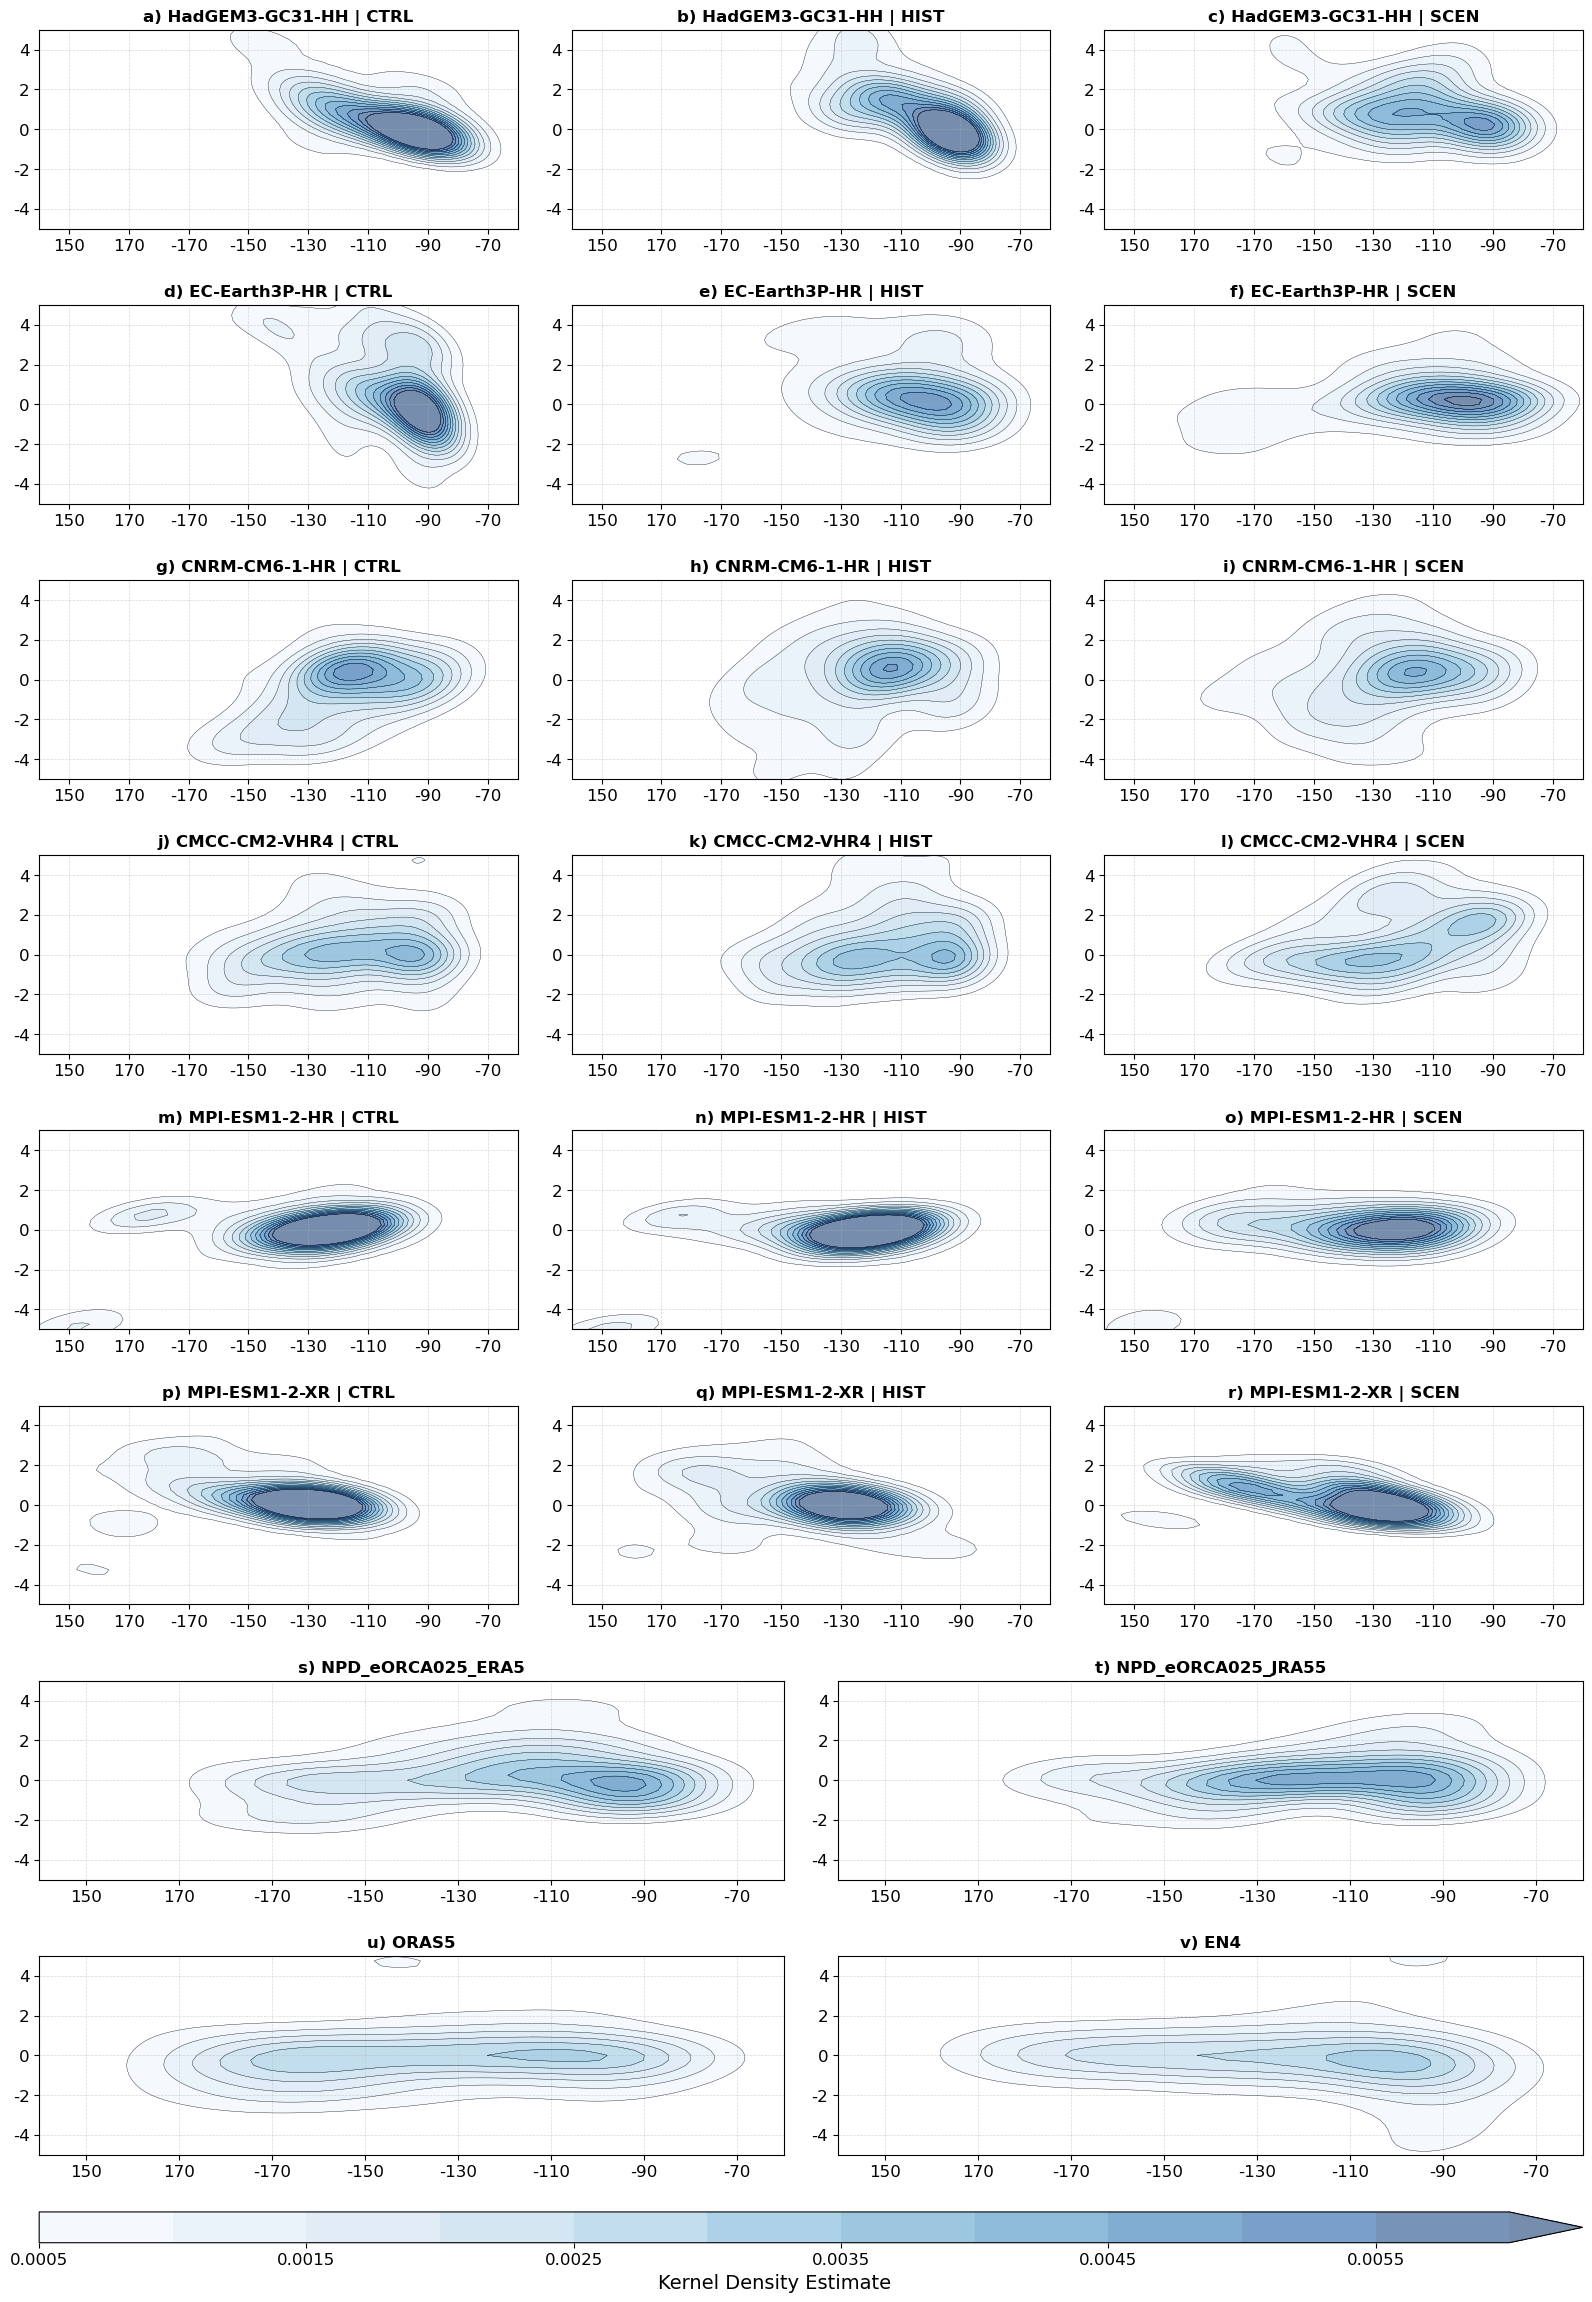

In [13]:
# =============================================================================
# READING IN AND COMBINING THE GAUSSIAN-KDE PEAK-LOCATION DENSITIES (BOTH EVAL PERIODS)
# =============================================================================
# CTRL/HIST (+ NPD/OBS) come from the HIST_EVAL file, SCEN from the FUTR_EVAL file
GAUSS_KDE_HIST = xr.open_dataset(f'{DATA_DIR}GAUSS_KDE_5S5N_HIST_EVAL_1979-2014.nc')
GAUSS_KDE_SCEN = xr.open_dataset(f'{DATA_DIR}GAUSS_KDE_5S5N_FUTR_EVAL_2015-2050.nc')
# Combined along 'dataset': {model}_CTRL / _HIST / _SCEN, NPD runs and OBS products
GAUSS_KDE = xr.concat([GAUSS_KDE_HIST, GAUSS_KDE_SCEN], dim = 'dataset')

# =============================================================================
# FIGURE C6 & C7: KDE OF PEAK-|SSTA| LOCATIONS DURING ENSO MONTHS (CTRL/HIST/SCEN, + OBS + NPD)
# =============================================================================
# Each KDE is fitted to the lon/lat of the maximum surface |SSTA| (5S-5N) in every El Niño / La Niña month
# (see compute_enso_peak_kde in utils.py)

# Contour levels and colorbar ticks for the KDE
levels_kde = list(np.arange(0.0005, 0.0065, 0.0005))
ticks_kde  = list(np.arange(0.0005, 0.0065, 0.001))

# Creating a meshgrid of longitudes and latitudes for the contour plots
lons, lats = np.meshgrid(GAUSS_KDE['lon'], GAUSS_KDE['lat'])
lon_ticks  = np.arange(150, 310, 20)
lon_labels = np.where(lon_ticks > 180, lon_ticks - 360, lon_ticks) # Longitudes > 180 are labelled as negative (degrees west)
lat_ticks  = np.arange(-4, 6, 2)

# Helper function to draw a single KDE panel (filled + line contours) with shared axis formatting
def draw_kde_panel(ax, dataset_name, phase, cmap = 'YlOrRd'):
    """
    Draw one KDE panel (filled and line contours) with shared axis formatting.

    Uses the global 'GAUSS_KDE' dataset and the contour levels, grid and ticks defined above.

    Parameters
    ----------
    ax (matplotlib.axes.Axes) : Axis to plot on.
    dataset_name (str)        : Dataset in 'GAUSS_KDE'.
    phase (str)               : 'EL-NINO' or 'LA-NINA'.
    cmap (str)                : Colormap of the filled contours. Default is 'YlOrRd'.

    Returns
    -------
    matplotlib.contour.QuadContourSet : Filled contours, used for the shared colorbar.
    """
    da   = GAUSS_KDE['GAUSS_KDE'].sel(dataset = dataset_name, enso_phase = phase)
    cbar = ax.contourf(lons, lats, da, cmap = cmap, levels = levels_kde, extend = 'max', alpha = 0.55)
    ax.contour(lons, lats, da, colors = 'k', levels = levels_kde, linewidths = 0.25)
    # Axis styling
    ax.set_xticks(lon_ticks)
    ax.set_xticklabels(lon_labels, fontsize = 12)
    ax.set_yticks(lat_ticks)
    ax.set_yticklabels(lat_ticks, fontsize = 12)
    ax.grid(visible = True, linestyle = '--', linewidth = 0.5, alpha = 0.5)
    return cbar

# Figure ID and colormap of each ENSO phase
KDE_PHASES = {'EL-NINO': {'fig_id': 'C6', 'cmap': 'Reds'},
              'LA-NINA': {'fig_id': 'C7', 'cmap': 'Blues'}}

# Looping through the two ENSO phases (El Niño and La Niña) to create two separate figures (C6 and C7)
for phase, cfg in KDE_PHASES.items():
    # 8 x 6 grid (see PANEL_SPECS)
    fig = plt.figure(figsize = (16, 22))
    gs  = fig.add_gridspec(8, 6)
    axes = []

    # One panel per dataset, labelled a, b, c, ...
    for label, (dataset_name, title, row, cols, _) in zip(string.ascii_lowercase, PANEL_SPECS):
        ax   = fig.add_subplot(gs[row, cols])
        cbar = draw_kde_panel(ax, dataset_name, phase = phase, cmap = cfg['cmap'])
        ax.set_title(f'{label}) {title}', fontsize = 12, fontweight = 'bold')
        axes.append(ax)

    # Layout and shared colorbar
    fig.tight_layout(h_pad = 2.25, w_pad = 2)
    # Shared colorbar below all panels
    add_colorbar(fig, axes = np.array(axes), mappable = cbar, label = 'Kernel Density Estimate',
                ticks = ticks_kde, side = 'bottom', height = 0.014, pad = 0.04,
                labelsize = 14, ticksize = 12)
    fig.savefig(f"{FIG_DIR}figure_{cfg['fig_id']}.png", bbox_inches = 'tight', dpi = 300)

### Figure C8: Vertical structure of temperature anomalies in Nino 3.4 (depth-time Hovmöller) in models and observation-based products for the historical (1979-2014) and future (2015-2050) periods

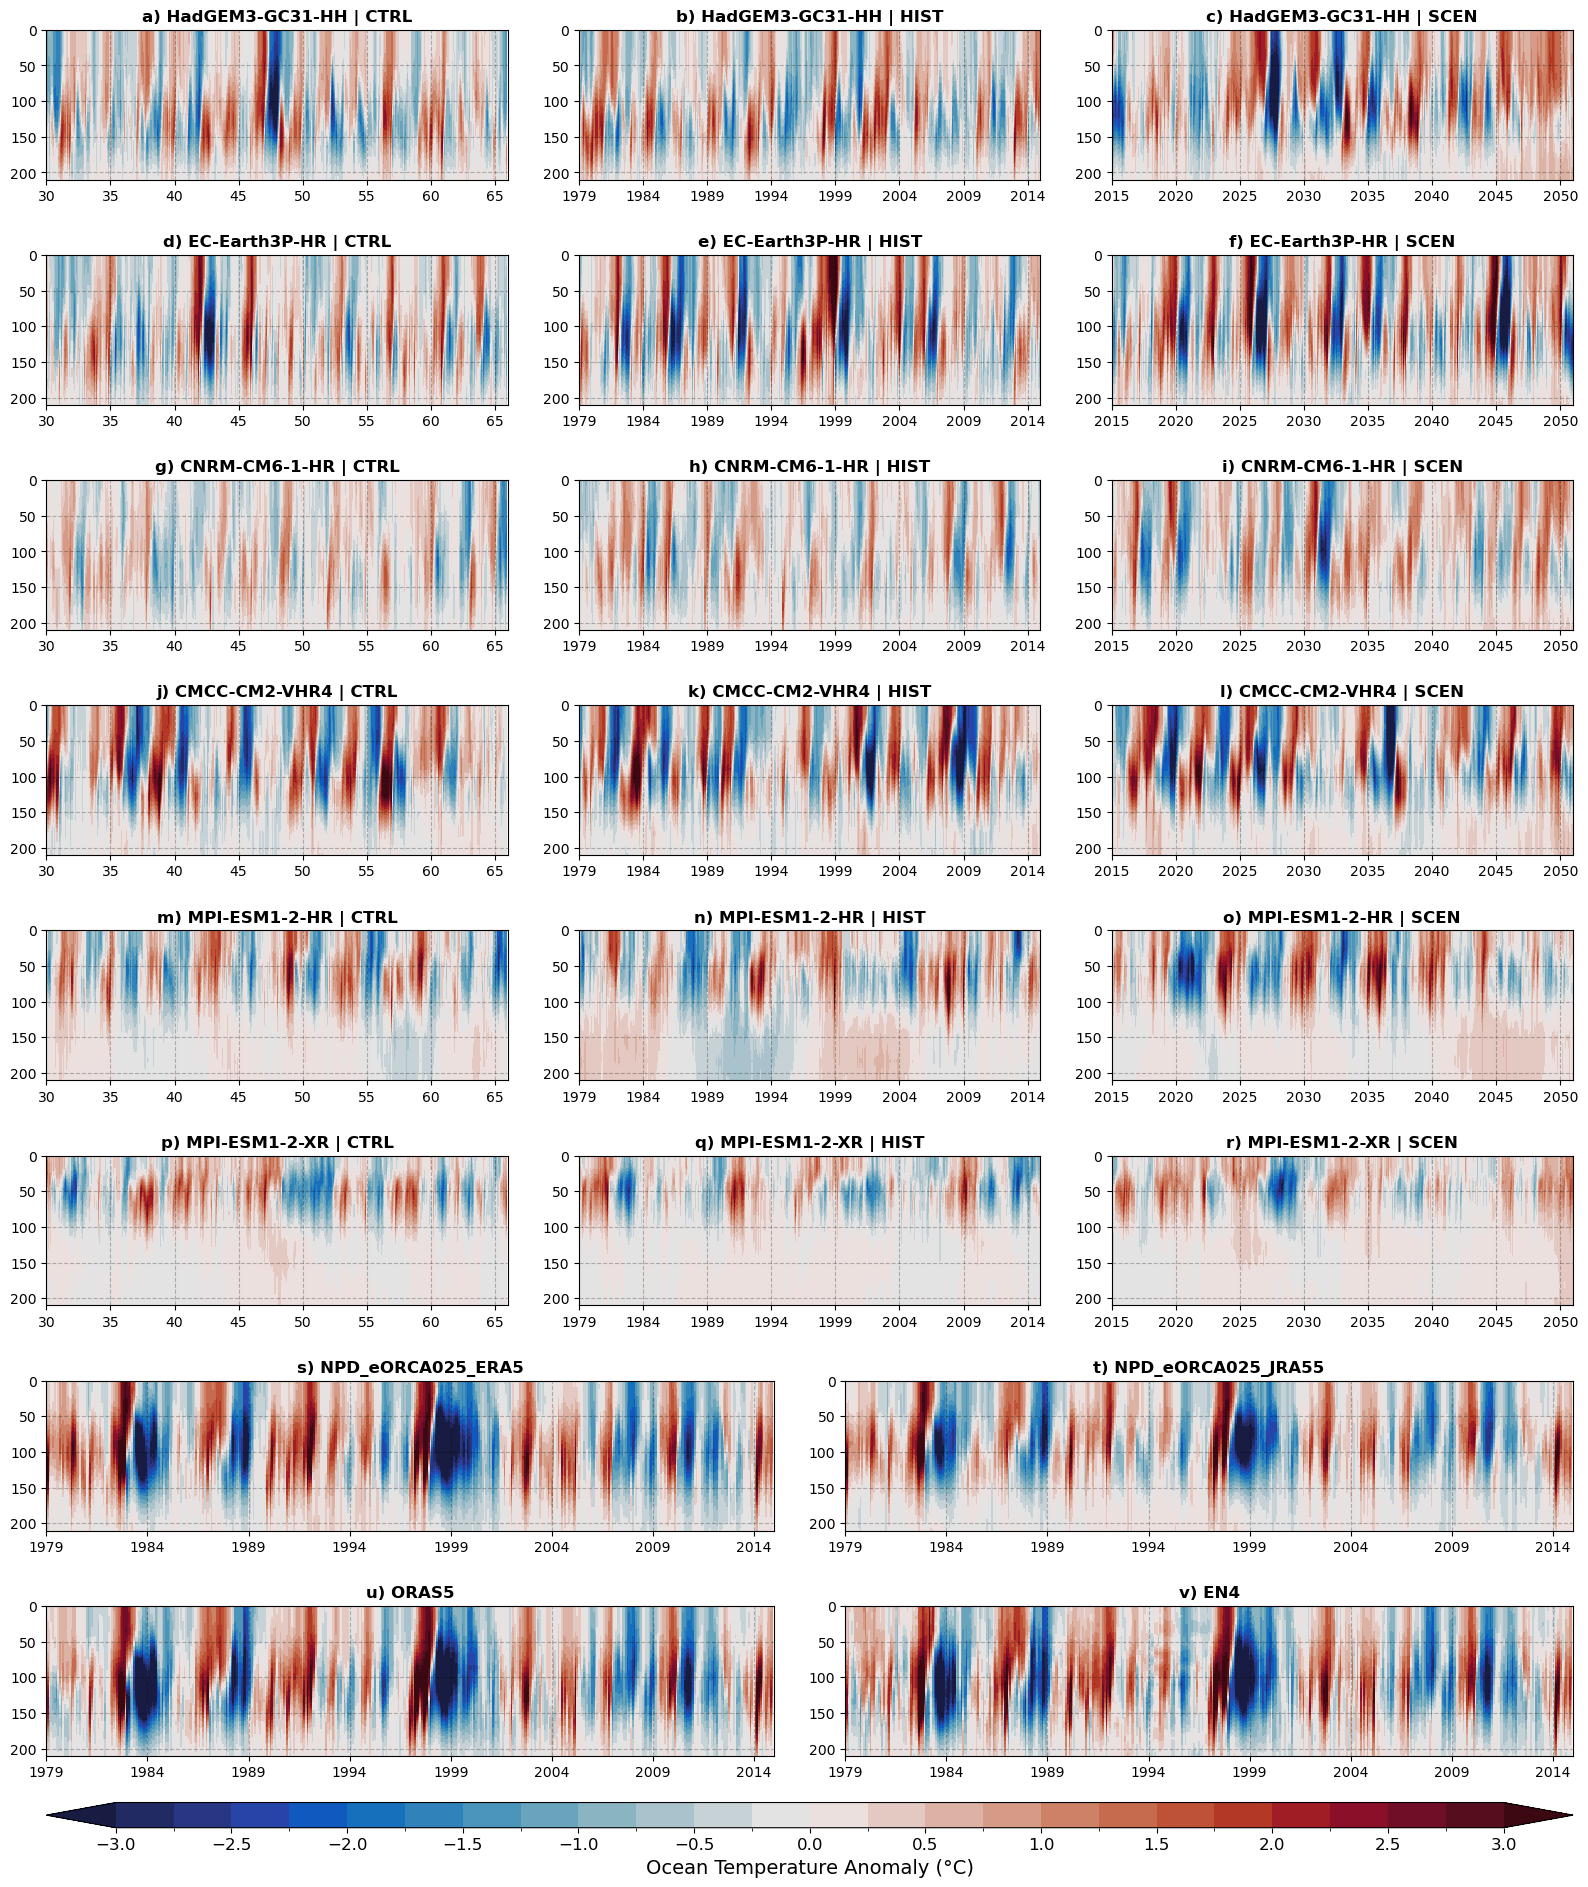

In [ ]:
# =============================================================================
# READING IN AND COMBINING THE N34 DEPTH-TIME HOVMOLLERS (BOTH EVAL PERIODS)
# =============================================================================
# CTRL/HIST (+ NPD/OBS) come from the HIST_EVAL file, SCEN from the FUTR_EVAL file
N34_HOV_HIST = xr.open_dataset(f'{DATA_DIR}N34_HOV_ZVT_TOP300M_HIST_EVAL_1979-2014.nc')
N34_HOV_SCEN = xr.open_dataset(f'{DATA_DIR}N34_HOV_ZVT_TOP300M_FUTR_EVAL_2015-2050.nc')
N34_HOV = xr.concat([N34_HOV_HIST, N34_HOV_SCEN], dim = 'dataset', join = 'outer')

# =============================================================================
# FIGURE C8: N34 OCEAN-TEMPERATURE-ANOMALY HOVMOLLERS (CTRL/HIST/SCEN, + OBS + NPD)
# =============================================================================
levels_hov = np.arange(-3, 3.01, 0.25)
ticks_hov  = np.arange(-3, 3.01, 0.5)

# Per-experiment x-axis configs: time-axis limits, tick positions and tick labels. CTRL is plotted on the same 1979-2014
# time axis as HIST, but its ticks are relabelled as model years 30-65 (offset of 30, as model_year_offset in utils.format_axis)
hov_periods = {'CTRL': ('1979-01-01', '2014-12-31'),
               'HIST': ('1979-01-01', '2014-12-31'),
               'SCEN': ('2015-01-01', '2050-12-31')}
xaxis_cfg = {}
for exp, (start, end) in hov_periods.items():
    ticks = pd.date_range(start = start, end = end, freq = '5YS')
    xaxis_cfg[exp] = {'xlim': (pd.Timestamp(start), pd.Timestamp(end)), 'ticks': ticks,
                      'labels': [str(t.year) for t in ticks]}
xaxis_cfg['CTRL']['labels'] = [str(y) for y in range(30, 66, 5)]

# Helper function to draw a single Hovmöller panel (filled contour) with shared axis formatting
def draw_hov_panel(ax, dataset_name, exp):
    """
    Draw one Hovmöller panel (filled contour) with shared axis formatting.

    Uses the global 'N34_HOV' dataset, the contour levels and 'xaxis_cfg' defined above.

    Parameters
    ----------
    ax (matplotlib.axes.Axes) : Axis to plot on.
    dataset_name (str)        : Dataset in 'N34_HOV'.
    exp (str)                 : Experiment type ('CTRL', 'HIST' or 'SCEN') that selects the x-axis configuration.

    Returns
    -------
    matplotlib.cm.ScalarMappable : Plot object used for the shared colorbar.
    """
    da   = N34_HOV['anomaly'].sel(dataset = dataset_name)
    cbar = da.plot(ax = ax, x = 'time', y = 'depth', levels = levels_hov, extend = 'both',
                   cmap = cmocean.cm.balance, add_colorbar = False)
    # Axes styling (the data span 0-300 m; only the top 210 m are shown)
    ax.set_ylim(0, 210)
    ax.invert_yaxis()
    # x-axis limits, ticks and labels of this experiment type
    ax.set_xlim(xaxis_cfg[exp]['xlim'])
    ax.set_xticks(xaxis_cfg[exp]['ticks'])
    ax.set_xticklabels(xaxis_cfg[exp]['labels'], fontsize = 10)
    ax.tick_params(axis = 'both', which = 'major', labelsize = 10)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.grid(True, ls = '--', color = 'k', alpha = 0.25)
    return cbar

# 8 x 6 grid (see PANEL_SPECS)
fig = plt.figure(figsize = (16, 18))
gs  = fig.add_gridspec(8, 6)
axes = []

# One panel per dataset, labelled a, b, c, ...; the experiment type picks the x-axis config (NPD/OBS follow HIST)
for label, (dataset_name, title, row, cols, exp) in zip(string.ascii_lowercase, PANEL_SPECS):
    ax   = fig.add_subplot(gs[row, cols])
    cbar = draw_hov_panel(ax, dataset_name, exp)
    ax.set_title(f'{label}) {title}', fontsize = 12, fontweight = 'bold')
    axes.append(ax)

# Layout and shared colorbar
fig.tight_layout(h_pad = 2.25, w_pad = 2)
# Shared colorbar below all panels
add_colorbar(fig, axes = np.array(axes), mappable = cbar, label = 'Ocean Temperature Anomaly (°C)',
             ticks = ticks_hov, side = 'bottom', height = 0.014, pad = 0.04,
             labelsize = 14, ticksize = 12)
fig.savefig(f'{FIG_DIR}figure_C8.png', bbox_inches = 'tight', dpi = 300)